# Assignment 1. Data Manipulation and Visualization  

*Foundations of Data Science*  
*Dr. Khalaj (Fall 2025)*  

*For your questions refer to alireza.sedaghat.ar@gmail.com or @Alirez4s on Telegram*

### Description
In this homework you are supposed to get comfortable (or make sure that you are!) with the basic Python tools frequently used in data science.  

### Information  
Complete the information box below.

In [ ]:
# Personal identifiers have been omitted from this public portfolio copy.
full_name = ""
student_id = ""


### Import necessary packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as ss
import seaborn as sns
import re
import string
from bs4 import BeautifulSoup 
import requests 
import matplotlib.dates as mdates
from scipy import stats 
from wordcloud import WordCloud
from IPython.display import display
from sklearn.preprocessing import LabelEncoder
from scipy.stats import pearsonr
from wordcloud import WordCloud
from bs4 import BeautifulSoup
from datetime import datetime
import matplotlib.dates as mdates
from scipy.stats import pearsonr, f_oneway

# 1. Let's Talk Business!

Storing customer and transaction data is crucial for e-commerce businesses as it enables them to understand and anticipate customer needs, optimize operations, and enhance the overall shopping experience. By collecting and analyzing data such as purchase history, browsing behavior, and demographic information, e-commerce platforms can personalize marketing efforts, recommend products, and improve customer retention. Additionally, transaction data helps in managing inventory, detecting fraudulent activities, and ensuring secure payment processing

This dataset contains the official transactions and customer data for a certain E-Commerce. The schema of the dataset can be shown in the following diagram.

<div style="text-align: center;">
<img src="./data/Q1/commerce_schema.png" alt="commerce-schema" width="750"/>
</div>

In this task you have to apply the following Data Wrangling pipeline:
* Load your data into `Pandas`  

* Explore it and clean its dirty parts
* Use it to answer a set of queries

Each of these subtasks are described in detail below.

## 1.1 Loading Phase

Load all of the sheets in the excel file to multiple `Pandas` dataframes in the directory `data/Q1`

In [3]:
excel_data = pd.ExcelFile("data\Q1\E-commerce_data.xlsx")
dataframes = {}
    
for sheet in excel_data.sheet_names:
    data = pd.read_excel(excel_data, sheet_name=sheet)
    dataframes[sheet] = data


## 1.2 Cleaning Phase

Explore the following columns from your dataset:

* transactions: year  

* transactions: branch_id
  
Answer the following questions using data visualizations and manipulations. The code for this part is required alongside your explanations either in comments or markdown.  

1. What is the time range of the transactions?  
2. What is the median branch in terms of transaction count?
3. Do you see any inconsistencies? 
4. Provide code that detects and cleans such inconsistencies and validates the coherence of your dataset. 

      Unnamed: 0  transaction_id  customer_id transaction_date  \
3              3               4          695      20240-01-26   
88            88              89            2      20230-10-21   
124          124             125          395      20240-05-14   
136          136             137          257      20230-11-06   
142          142             143          513      20240-01-14   
...          ...             ...          ...              ...   
4839        4839            4840          606      20240-05-20   
4910        4910            4911          930      20240-07-06   
4935        4935            4936          491      20240-05-09   
4975        4975            4976          190      20220-10-23   
4978        4978            4979          858      20230-12-26   

     transaction_status coupon_name  burn_date  branch_id  
3            subscribed     Wzf-897        NaT        2.0  
88           subscribed     SSV-196        NaT        4.0  
124              burned    

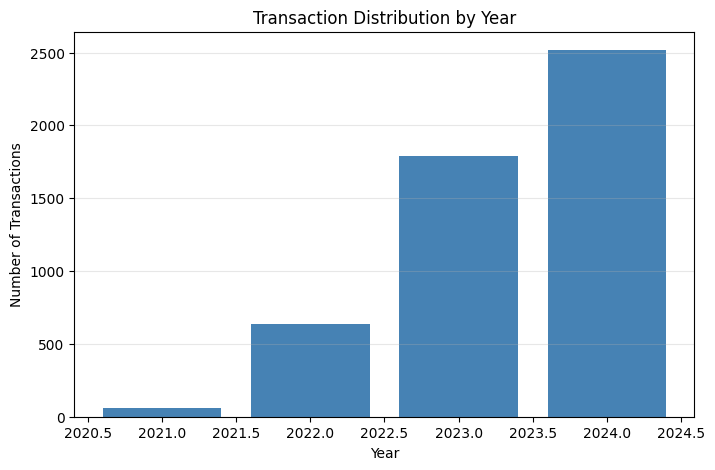


Total unique branches: 10
Median transactions per branch: 493.5


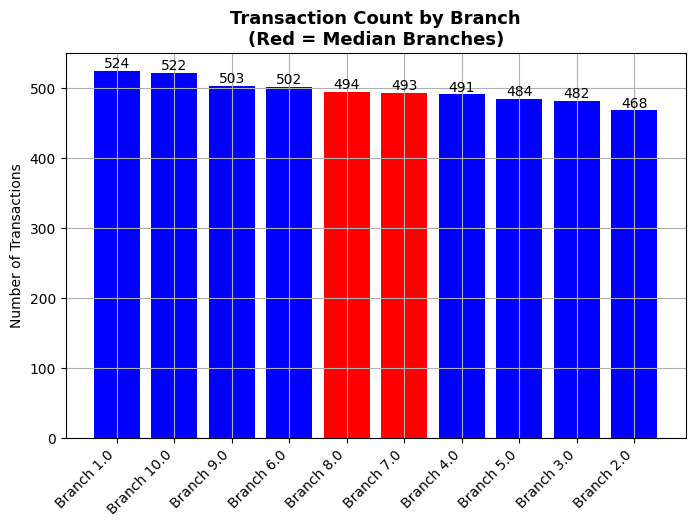

In [4]:
transactions = dataframes['transactions']
#checking for invalid date formats
invalid_dates = transactions[~transactions['transaction_date'].str.match(r'^\d{4}-\d{2}-\d{2}$', na=False)]
print(invalid_dates)
transactions['transaction_date'] = transactions['transaction_date'].str.replace(r'^(\d{4})\d-', r'\1-', regex=True)
transaction_year = pd.to_datetime(transactions['transaction_date'], format='%Y-%m-%d')
transaction_year = transaction_year.dt.year
#Checking for inconsistencies
missing_years = transaction_year.isna().sum()
print(f"Number of missing year values: {missing_years}")

year_min = transaction_year.min()
year_max = transaction_year.max()
year_range = year_max - year_min

print(f"  Earliest year: {year_min}")
print(f"  Latest year: {year_max}")
print(f"  Time range: {year_range} years")

# visualization of transaction count by year
fig, ax = plt.subplots(figsize=(8, 5))

year_counts = transaction_year.value_counts().sort_index()
ax.bar(year_counts.index, year_counts.values, color='steelblue')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Transactions')
ax.set_title('Transaction Distribution by Year')
ax.grid(axis='y', alpha=0.3)

plt.show()

## Branch Id analysis
branch_counts = transactions['branch_id'].value_counts().sort_values(ascending=False)

print(f"\nTotal unique branches: {len(branch_counts)}")
median_count = branch_counts.median()
print(f"Median transactions per branch: {median_count}")

## visualization
fig, ax = plt.subplots(figsize=(8, 5))
median_branch_lower = branch_counts.index[4]
median_count_lower = branch_counts.iloc[4]
median_branch_upper = branch_counts.index[5]
median_count_upper = branch_counts.iloc[5]

branch_counts_desc = branch_counts.sort_values(ascending=False)
colors = ['red' if i in [4, 5] else 'blue' for i in range(len(branch_counts_desc))]

ax.bar(range(len(branch_counts_desc)), branch_counts_desc.values, color=colors)
ax.set_xticks(range(len(branch_counts_desc)))
ax.set_xticklabels([f'Branch {b}' for b in branch_counts_desc.index], rotation=45, ha='right')
ax.set_ylabel('Number of Transactions')
ax.set_title('Transaction Count by Branch\n(Red = Median Branches)', fontweight='bold', fontsize=13)
ax.grid()
for i, (branch, count) in enumerate(branch_counts_desc.items()):
    ax.text(i, count, str(count), ha='center', va='bottom')
plt.show()

**Explain your approach and assumptions once this section is completed.**

Q1- According to values obtained above,The time range of transactions is from 2021 to 2024, and transaction counts increase each year, peaking in 2024.

Q2- There are 10 branch IDs; branches 7 and 8 are the median in transaction count, branch 1 has the most, and branch 2 has the least.

Q3- Some inconsistencies were detected in the transaction date field due to invalid date formats (extra digits in the year).
These anomalies were identified and corrected using a regex  before conversion.
Also the number of missing years was checked and no missing year values were found in the dataset.

## 1.3. Querying phase

Answer the following queries using the functionality of `Pandas`:

* List the names of the cities of customers who have spent coupons ending with a number less than 100. (*Hint: Find a smart way to distinguish which coupons contain numbers less than 100*).  

* Plot the distribution of merchants' transactions as a (horizontal) bar chart. Restrict yourself to the 5 merchants with their names in the x-axis.

* Create a line plot of the mean transaction counts in a month, through time. add an area plot on top of the line plot depicting the minimum and maximum bounds in each month.

* Repeat the previous part but categorize the dataset by transcription_status first. Are there any visible trends in the consuming patterns of subscribed vs. burned customers?

Cities of customers who used coupons ending with a number less than 100:
0                 Mansoura
1                     Qena
2                 Ismailia
3      El-Mahalla El-Kubra
4                     Giza
              ...         
411                  Aswan
412                  Tanta
413                  Tanta
414                  Sohag
415                   Suez
Name: city_name, Length: 416, dtype: object


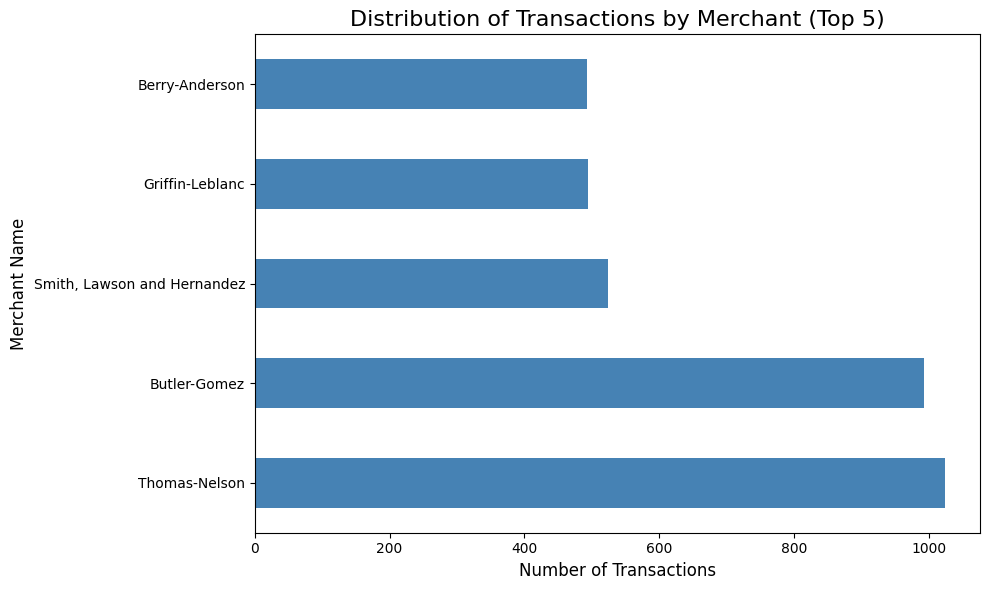

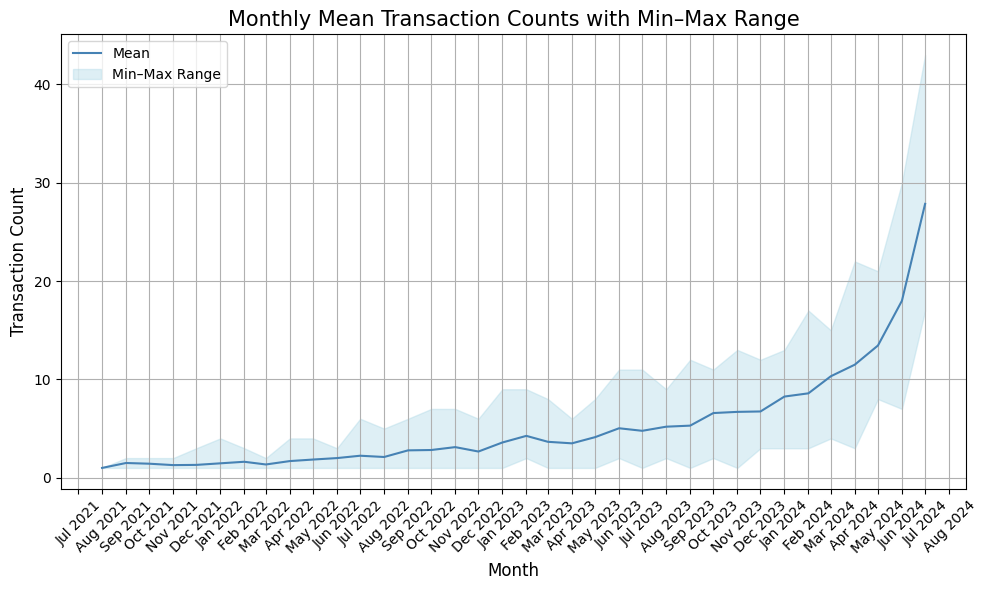

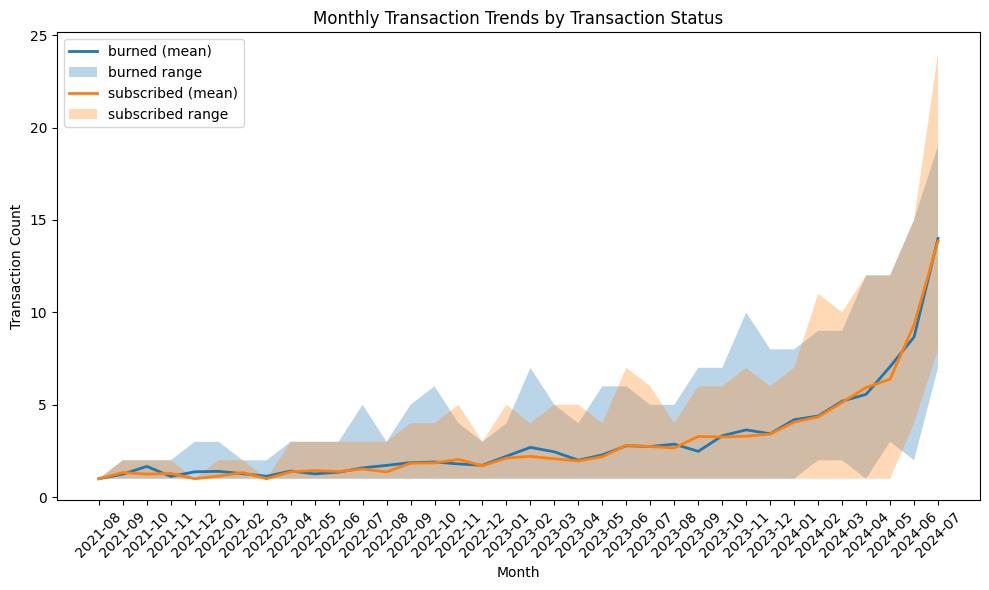

In [5]:
#part 1
# coupon ends with '-0xx'
low_coupon = transactions['coupon_name'].str.contains(r'-0\d+', regex=True)
low_coupon_transactions = transactions[low_coupon]
low_coupon_customers = low_coupon_transactions['customer_id']

customers = dataframes["customers"]
filtered_customers = customers[customers['customer_id'].isin(low_coupon_customers)]
cities = dataframes["cities"]
result = pd.merge(filtered_customers, cities, on='city_id', how='left')
city_names = result['city_name']
print("Cities of customers who used coupons ending with a number less than 100:")
print(city_names)

#part2
merged_branches = pd.merge(transactions, dataframes['branches'], on='branch_id', how='left')
merged_merchants = pd.merge(merged_branches, dataframes['merchants'], on='merchant_id', how='left')
merchant_transaction_counts = merged_merchants['merchant_name'].value_counts()
top_5_merchants = merchant_transaction_counts.head(5)

#plotting
plt.figure(figsize=(10, 6))
top_5_merchants.plot(kind='barh', color='steelblue')
plt.title('Distribution of Transactions by Merchant (Top 5)', fontsize=16)
plt.xlabel('Number of Transactions', fontsize=12)
plt.ylabel('Merchant Name', fontsize=12)
plt.tight_layout()
plt.show()

#part3
transactions['transaction_date'] = pd.to_datetime(transactions['transaction_date'], errors='coerce')
# Extract month and year
transactions['month'] = transactions['transaction_date'].dt.to_period('M')
daily_counts = transactions.groupby(transactions['transaction_date'].dt.date).size().reset_index(name='count')
daily_counts['month'] = pd.to_datetime(daily_counts['transaction_date']).dt.to_period('M')
monthly_all = daily_counts.groupby('month')['count'].agg(['mean', 'min', 'max']).reset_index()
monthly_all['month'] = monthly_all['month'].dt.to_timestamp()

plt.figure(figsize=(10, 6))
# Line plot
plt.plot(monthly_all['month'], monthly_all['mean'], color='steelblue', label='Mean')

#min–max range plot
plt.fill_between(
    monthly_all['month'],
    monthly_all['min'],
    monthly_all['max'],
    color='lightblue',
    alpha=0.4,
    label='Min–Max Range'
)

plt.title('Monthly Mean Transaction Counts with Min–Max Range', fontsize=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Transaction Count', fontsize=12)
plt.legend()
plt.grid()
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#part4
transactions['transaction_date'] = pd.to_datetime(transactions['transaction_date'], errors='coerce')
transactions['year_month'] = transactions['transaction_date'].dt.to_period('M')
daily_counts = transactions.groupby(['transaction_status', transactions['transaction_date'].dt.date]).size().reset_index(name='count')
daily_counts['year_month'] = pd.to_datetime(daily_counts['transaction_date']).dt.to_period('M')
monthly_stats = daily_counts.groupby(['transaction_status', 'year_month'])['count'].agg(['mean', 'min', 'max']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
for status, group in monthly_stats.groupby('transaction_status'):
    plt.plot(group['year_month'].astype(str), group['mean'], linewidth=2, label=f'{status} (mean)')
    plt.fill_between(group['year_month'].astype(str), group['min'], group['max'], alpha=0.3, label=f'{status} range')

plt.title('Monthly Transaction Trends by Transaction Status')
plt.xlabel('Month')
plt.ylabel('Transaction Count')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()




**Explain your approach and assumptions once this section is completed.**

Q1- In order to distinguish which coupons contain numbers less than 100, I used a regex pattern to detect numbers that start with 0 as their most significant digit. Using this approach, I was able to list the cities of the corresponding customers.

Q4- The general consuming pattern of both customer types shows an increasing trend over time. In the early months, burned customers made more transactions, but as time passed, the number of transactions by subscribed customers increased.

# 2. Canadian Cheese Directory!

The database of Canadian cheeses made from cow, goat, sheep or buffalo milk has been provided.

In this question you will again perform data wrangling and interpretation.

## 2.1 Loading Phase 

Load the csv file into a `DataFrame`

In [6]:
dataframe = pd.read_csv('data\Q2\cheese_data.csv')

## 2.2 Cleaning Phase 

Perform the following actions on the dataset.

1. Describe the type and the value range of each attribute.  
2. Indicate and transform the attributes that are `Categorical`.
3. Are there redundant columns in the dataset (i.e., are there columns whose value depends only on the value of another column)?
4. What are the possible pitfalls of having such columns?

Reduce *data redundancy* by extracting such columns to separate `DataFrames`. Which of the two formats (the initial one or the one with reduced data redundancy) is more susceptible to inconsistencies? At the end print for each `Dataframe` the *type of each column* and it's *shape*.

,Unnamed: 0,CheeseId,ManufacturerProvCode,ManufacturingTypeEn,MoisturePercent,FlavourEn,CharacteristicsEn,Organic,CategoryTypeEn,MilkTypeEn,MilkTreatmentTypeEn,RindTypeEn,CheeseName,FatLevel,FatIndex
count,1042.000000,1042.000000,1042,1042,1028.000000,801,643,1042.000000,1019,1041,977,721,1042,1042,1042.000000
unique,NaN,NaN,10,3,NaN,635,535,NaN,6,8,3,4,1038,2,NaN
top,NaN,NaN,QC,Industrial,NaN,Mild,Creamy,NaN,Firm Cheese,Cow,Pasteurized,No Rind,Boerenkaas,lower fat,NaN
freq,NaN,NaN,796,455,NaN,59,19,NaN,349,743,800,404,2,684,NaN
mean,520.500000,1560.633397,NaN,NaN,47.069747,NaN,NaN,0.095010,NaN,NaN,NaN,NaN,NaN,NaN,0.343570
std,300.943793,451.811164,NaN,NaN,9.592647,NaN,NaN,0.293369,NaN,NaN,NaN,NaN,NaN,NaN,0.475128
min,0.000000,228.000000,NaN,NaN,12.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,260.250000,1280.250000,NaN,NaN,40.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,520.500000,1548.500000,NaN,NaN,46.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,780.750000,1901.750000,NaN,NaN,52.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000



Categorical Columns (10):
  - ManufacturerProvCode
  - ManufacturingTypeEn
  - FlavourEn
  - CharacteristicsEn
  - CategoryTypeEn
  - MilkTypeEn
  - MilkTreatmentTypeEn
  - RindTypeEn
  - CheeseName
  - FatLevel

ManufacturerProvCode:
  Original values: 10
    0 = 'AB'
    1 = 'BC'
    2 = 'MB'
    3 = 'NB'
    4 = 'NL'
    5 = 'NS'
    6 = 'ON'
    7 = 'PE'
    8 = 'QC'
    9 = 'SK'

ManufacturingTypeEn:
  Original values: 3
    0 = 'Artisan'
    1 = 'Farmstead'
    2 = 'Industrial'

FlavourEn:
  Original values: 636

CharacteristicsEn:
  Original values: 536

CategoryTypeEn:
  Original values: 7
    0 = 'Firm Cheese'
    1 = 'Fresh Cheese'
    2 = 'Hard Cheese'
    3 = 'Semi-soft Cheese'
    4 = 'Soft Cheese'
    5 = 'Veined Cheeses'
    6 = 'nan'

MilkTypeEn:
  Original values: 9
    0 = 'Buffalo Cow'
    1 = 'Cow'
    2 = 'Cow and Goat'
    3 = 'Cow, Goat and Ewe'
    4 = 'Ewe'
    5 = 'Ewe and Cow'
    6 = 'Ewe and Goat'
    7 = 'Goat'
    8 = 'nan'

MilkTreatmentTypeEn:
  Origin

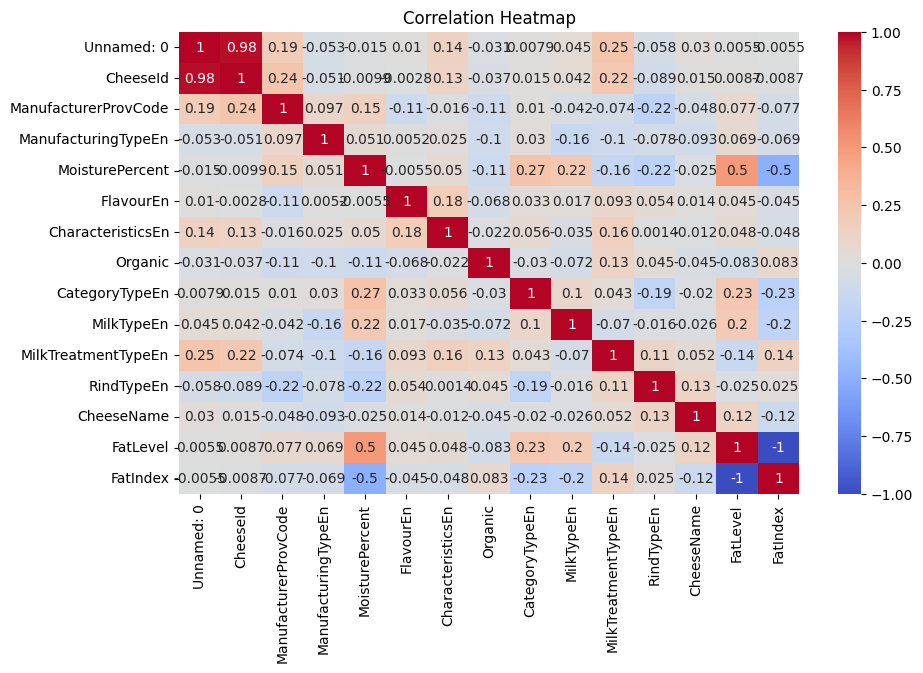


Highly correlated pairs (|correlation| >= 0.8):
  - Unnamed: 0 <-> CheeseId: 0.981
  - FatLevel <-> FatIndex: -1.000

Shape: 1042 rows × 15 columns
  • int64           : 14 columns
  • float64         :  1 columns

Shape: 1042 rows × 13 columns
  • int64           : 12 columns
  • float64         :  1 columns


In [7]:
#part1
display(dataframe.describe(include='all'))

#part2
categorical_columns = dataframe.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical Columns ({len(categorical_columns)}):")
for col in categorical_columns:
    print(f"  - {col}")

#Label encoding
df_labe = dataframe.copy()
label_encoders = {}

for col in categorical_columns:
    if col in dataframe.columns:
        le = LabelEncoder()
        dataframe[col] = le.fit_transform(dataframe[col])
        label_encoders[col] = le
        
        print(f"\n{col}:")
        print(f"  Original values: {dataframe[col].nunique()}")
        if dataframe[col].nunique() <= 20:
            for i, category in enumerate(le.classes_):
                print(f"    {i} = '{category}'")

#part3

numeric_col = dataframe.select_dtypes(include=[np.number])
#correlation matrix
corr_matrix = numeric_col.corr()
#heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#part4

threshold = 0.8
redundant_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) >= threshold:
            col1 = corr_matrix.columns[i]
            col2 = corr_matrix.columns[j]
            corr_value = corr_matrix.iloc[i, j]
            redundant_pairs.append((col1, col2, corr_value))

print(f"\nHighly correlated pairs (|correlation| >= {threshold}):")
for col1, col2, corr in redundant_pairs:
     print(f"  - {col1} <-> {col2}: {corr:.3f}")

cols_to_extract = set()
for col1, col2, corr in redundant_pairs:
    cols_to_extract.add(col2)

cols_to_keep = [col for col in dataframe.columns if col not in cols_to_extract]
df_noRedundant = dataframe[cols_to_keep].copy()

#part5
#Original Dataframe data shape
print(f"\nShape: {dataframe.shape[0]} rows × {dataframe.shape[1]} columns")
dtype_counts = dataframe.dtypes.value_counts()
for dtype, count in dtype_counts.items():
    print(f"  • {str(dtype):<15} : {count:2d} columns")
    
#Dataframe with no redundancy data shape
print(f"\nShape: {df_noRedundant.shape[0]} rows × {df_noRedundant.shape[1]} columns")
dtype_counts = df_noRedundant.dtypes.value_counts()
for dtype, count in dtype_counts.items():
    print(f"  • {str(dtype):<15} : {count:2d} columns")


**Explain your approach and assumptions once this section is completed.**

Q1. Using the describe() command, the type and value range of each attribute were analyzed. The output includes the max, min, mean, and standard deviation for each numerical column.

Q2. In the second part, I first identified the categorical columns. Then, using Label Encoding, I converted them into numerical format, assigning each unique category a numeric code.

Q3. To detect redundancy among attributes, I calculated the correlation matrix between all numerical columns and visualized it using a heatmap. Columns with correlation coefficients close to 1 show potential redundancy.

Q4. After identifying highly correlated columns, I applied a threshold of 0.8. Columns with correlation above this threshold were considered redundant and removed. As a result, the new DataFrame has two fewer columns, as confirmed by its shape. 
Some possible pitfalls of data redundancy include 1-unnecessary memory usage, which reduces system efficiency; 2-the inability to delete certain information without losing related data; 3-data inconsistencies; 4-slower data retrieval and increased complexity during updates since changes to redundant data must be made in multiple places.5-Redundancy can cause pose security and privacy risks
The redundant DataFrame is more susceptible to inconsistencies since each piece of data is stored in multiple places within the database. This makes it harder to insert, delete, or update records while maintaining data accuracy.
In conclusion, multiple copies of the same data can become inconsistent if they are not updated simultaneously, leading to inaccurate or unreliable information.

## 2.3 Querying Phase

Answer the following queries using the functionality of `Pandas`.

* Plot the **proportion** of **ManufacturingTypeEn**, **MoisturePercent**, **CategoryTypeEn**, **MilkTypeEn** columns in four subplots using pie diagrams.

* Categorize the dataframe by the **FatIndex**. Calculate the proportion of each FatIndex in the previous columns (ManufacturingTypeEn, MoisturePercent, CategoryTypeEn, MilkTypeEn) and present your results in a **stacked bar chart**.

* Separate the MoisturePercent values into two intervals that have (approximately) the same number of cheese products in the dataset. Categorize the dataset based on MoistureIndex, FatIndex, ManufacturingTypeEn, MoisturePercent, CategoryTypeEn, MilkTypeEn and calculate the proportions of each category. Represent your results in a separate `DataFrame`.

* Is there any row that is slightly more popular than the others? Do you see any correlation between the cheese attributes and their popularity?


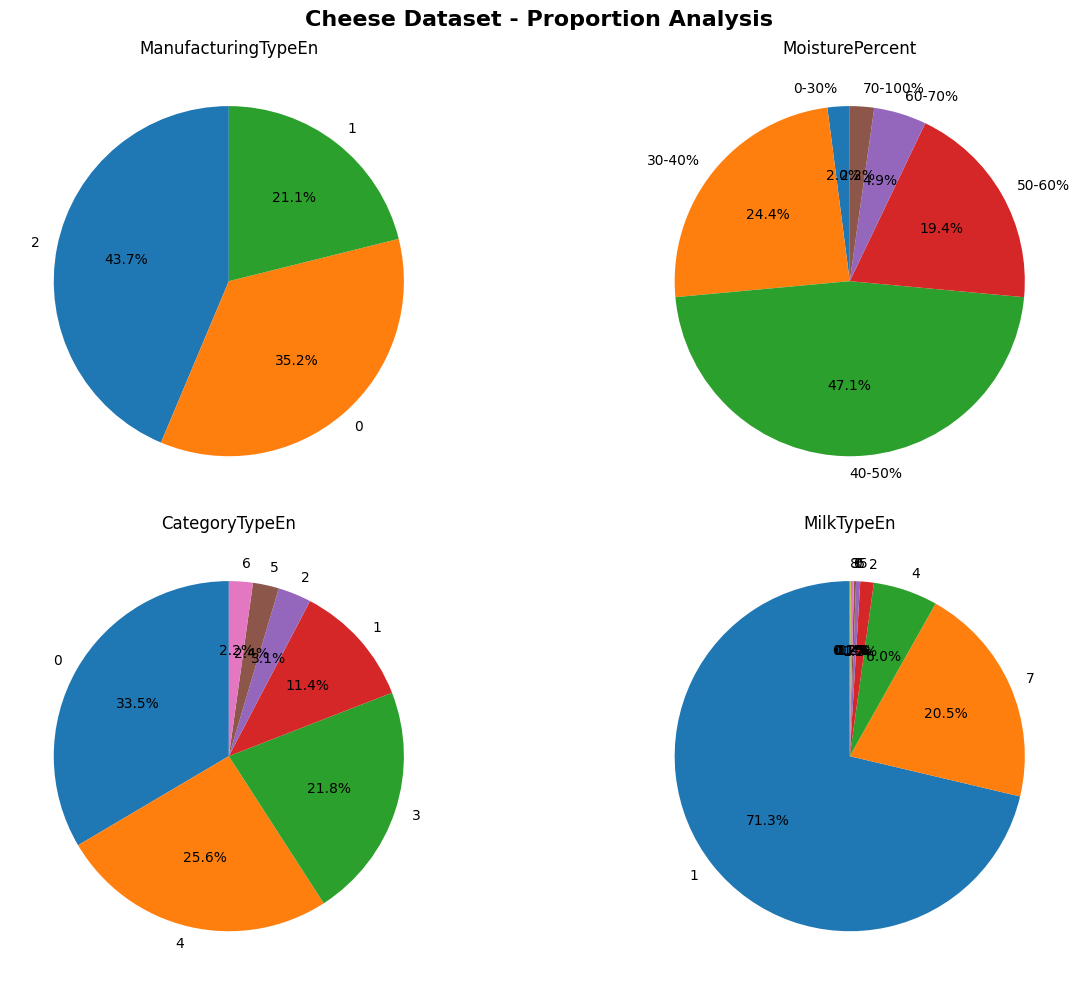

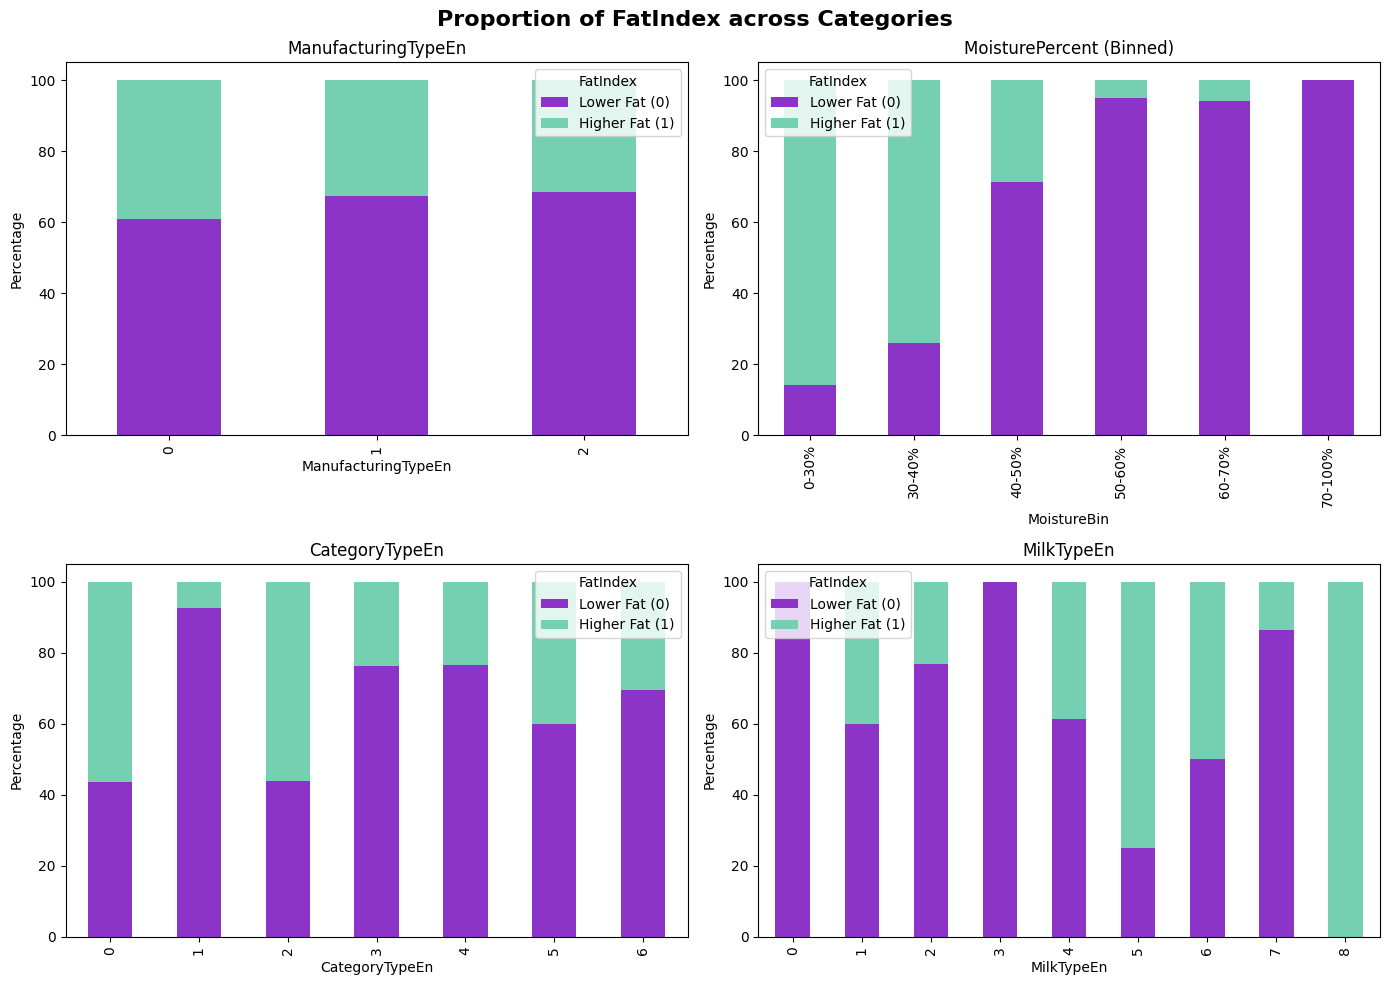


MoistureIndex:
  0.0: 536 (52.14%)
  1.0: 492 (47.86%)

FatIndex:
  0: 684 (65.64%)
  1: 358 (34.36%)

ManufacturingTypeEn:
  0: 367 (35.22%)
  1: 220 (21.11%)
  2: 455 (43.67%)

CategoryTypeEn:
  0: 349 (33.49%)
  1: 119 (11.42%)
  2: 32 (3.07%)
  3: 227 (21.79%)
  4: 267 (25.62%)
  5: 25 (2.40%)
  6: 23 (2.21%)

MilkTypeEn:
  0: 2 (0.19%)
  1: 743 (71.31%)
  2: 13 (1.25%)
  3: 1 (0.10%)
  4: 62 (5.95%)
  5: 4 (0.38%)
  6: 2 (0.19%)
  7: 214 (20.54%)
  8: 1 (0.10%)


In [8]:
#part1

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Cheese Dataset - Proportion Analysis', fontsize=16, fontweight='bold')
axes = axes.flatten()

data = dataframe['ManufacturingTypeEn'].value_counts()
axes[0].pie(data.values, labels=data.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('ManufacturingTypeEn')

moisture_data = dataframe["MoisturePercent"].dropna()
bins = [0, 30, 40, 50, 60, 70, 100]
labels = ['0-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-100%']
moisture_binned = pd.cut(moisture_data, bins=bins, labels=labels, include_lowest=True)
data = moisture_binned.value_counts().sort_index()
axes[1].pie(data.values, labels=data.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title("MoisturePercent")

data = dataframe['CategoryTypeEn'].value_counts()
axes[2].pie(data.values, labels=data.index, autopct='%1.1f%%', startangle=90)
axes[2].set_title('CategoryTypeEn')

data = dataframe['MilkTypeEn'].value_counts()
axes[3].pie(data.values, labels=data.index, autopct='%1.1f%%', startangle=90)
axes[3].set_title('MilkTypeEn')

plt.tight_layout()
plt.show()

#part2

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Proportion of FatIndex across Categories', fontsize=16, fontweight='bold')
axes = axes.flatten()
colors = ["#8D34C8", "#75CFB1"]
crosstab = pd.crosstab(dataframe['ManufacturingTypeEn'], dataframe['FatIndex'])
proportions = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
proportions.plot(kind='bar', stacked=True, ax=axes[0],color=colors)
axes[0].set_title('ManufacturingTypeEn')
axes[0].set_ylabel('Percentage')
axes[0].legend(title='FatIndex', labels=['Lower Fat (0)', 'Higher Fat (1)'])

moisture_data = dataframe[['MoisturePercent', 'FatIndex']].dropna()
bins = [0, 30, 40, 50, 60, 70, 100]
labels = ['0-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-100%']
moisture_data['MoistureBin'] = pd.cut(moisture_data['MoisturePercent'], bins=bins, labels=labels)
crosstab = pd.crosstab(moisture_data['MoistureBin'], moisture_data['FatIndex'])
proportions = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
proportions.plot(kind='bar', stacked=True, ax=axes[1],color=colors)
axes[1].set_title('MoisturePercent (Binned)')
axes[1].set_ylabel('Percentage')
axes[1].legend(title='FatIndex', labels=['Lower Fat (0)', 'Higher Fat (1)'])

crosstab = pd.crosstab(dataframe['CategoryTypeEn'], dataframe['FatIndex'])
proportions = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
proportions.plot(kind='bar', stacked=True, ax=axes[2],color=colors)
axes[2].set_title('CategoryTypeEn')
axes[2].set_ylabel('Percentage')
axes[2].legend(title='FatIndex', labels=['Lower Fat (0)', 'Higher Fat (1)'])

crosstab = pd.crosstab(dataframe['MilkTypeEn'], dataframe['FatIndex'])
proportions = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
proportions.plot(kind='bar', stacked=True, ax=axes[3],color=colors)
axes[3].set_title('MilkTypeEn')
axes[3].set_ylabel('Percentage')
axes[3].legend(title='FatIndex', labels=['Lower Fat (0)', 'Higher Fat (1)'])

plt.tight_layout()
plt.show()

#part3

moisture_clean = dataframe['MoisturePercent'].dropna()
median_moisture = moisture_clean.median()
dataframe['MoistureIndex'] = pd.cut(dataframe['MoisturePercent'], bins=[0, median_moisture, 100], labels=[0, 1],include_lowest=True)
dataframe['MoistureIndex'] = dataframe['MoistureIndex'].astype('float')

categories = ['MoistureIndex', 'FatIndex', 'ManufacturingTypeEn', 'CategoryTypeEn', 'MilkTypeEn']

proportion_results = []

for category in categories:
    print(f"\n{category}:")
    value_counts = dataframe[category].value_counts().sort_index()
    total = value_counts.sum()
    for value, count in value_counts.items():
        proportion = (count / total) * 100
        proportion_results.append({'Category': category,'Value': value, 'Count': count,'Proportion': proportion})
        print(f"  {value}: {count} ({proportion:.2f}%)")

df_proportions = pd.DataFrame(proportion_results)


**Explain your approach and assumptions once this section is completed.**

The results show that cheeses with lower fat content, produced by industrial manufacturers, categorized as Firm Cheese, and made from cow’s milk are the most popular among all types. 

# 3. Business Analyst Job Listings  

## 3.1 Loading Phase

As we will learn further in the course, a considerable source of data is free internet information which is crawled!

4092 business analyst job listings scraped from glassdoor are provided at `data/Q3`. Load the data in a `DataFrame`

In [12]:
dataframe3 = pd.read_csv('data\Q3\BusinessAnalyst.csv')

## 3.2 Cleaning Phase

Perform the following actions on the dataset.

1. Describe the type and the value range of each attribute.  
2. Indicate and transform the attributes that are `Categorical`.
3. Replace **Salary Estimate** column with expected salary.
4. Explore lower and upper bounds of **Ratings** column. Fix any inconsitensies.
5. Provide a numerical column for expected company size.

In [13]:
#part1
display(dataframe3.describe(include='all'))

#part2
categorical_columns = dataframe3.select_dtypes(include=['object']).columns.tolist()

columns_to_exclude = ['Size', 'Salary Estimate', 'Rating']
for col in columns_to_exclude:
    if col in categorical_columns:
        categorical_columns.remove(col)

print(f"\nCategorical Columns to be Label Encoded ({len(categorical_columns)}):")
for col in categorical_columns:
    print(f"  - {col}")

#Label encoding

label_encoders = {}

for col in categorical_columns:
    if col in dataframe3.columns:
        le = LabelEncoder()
        dataframe3[col] = le.fit_transform(dataframe3[col])
        label_encoders[col] = le
        
        print(f"\n{col}:")
        print(f"  Original values: {dataframe3[col].nunique()}")
        if dataframe3[col].nunique() <= 20:
            for i, category in enumerate(le.classes_):
                print(f"    {i} = '{category}'")

#part3

dataframe3['Salary Estimate'] = dataframe3['Salary Estimate'].astype(str)
dataframe3['Salary Estimate'] = dataframe3['Salary Estimate'].str.replace(r'\(.*\)', '', regex=True)
dataframe3['Salary Estimate'] = dataframe3['Salary Estimate'].str.replace('$', '', regex=False)
dataframe3['Salary Estimate'] = dataframe3['Salary Estimate'].str.replace('K', '', regex=False)
dataframe3['Salary Estimate'] = dataframe3['Salary Estimate'].str.strip()

def extract_min_salary(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if x == '' or x.lower() == 'nan':
        return np.nan
    if '-' in x:
        try:
            return float(x.split('-')[0].strip())
        except ValueError:
            return np.nan
    else:
        return pd.to_numeric(x, errors='coerce')

def extract_max_salary(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if x == '' or x.lower() == 'nan':
        return np.nan
    if '-' in x:
        try:
            return float(x.split('-')[1].strip())
        except ValueError:
            return np.nan
    else:
        return pd.to_numeric(x, errors='coerce')


dataframe3['Min'] = dataframe3['Salary Estimate'].apply(extract_min_salary)
dataframe3['Max'] = dataframe3['Salary Estimate'].apply(extract_max_salary)
dataframe3['Expected Salary'] = (dataframe3['Min'] + dataframe3['Max']) / 2
dataframe3['Salary Estimate'] = dataframe3['Expected Salary']
dataframe3.drop(['Min', 'Max', 'Expected Salary'], axis=1, inplace=True)

print("\nThe dataframe after transforming categorical columns to numerical: ")
display(dataframe3.describe(include='all'))
 
#part4
# Rating 

dataframe3['Rating'] = pd.to_numeric(dataframe3['Rating'], errors='coerce')

print("\nRating Statistics:")
print(dataframe3['Rating'].describe())
print(f"\nMissing Values: {dataframe3['Rating'].isna().sum()}")


# Fix 
def fix_rating(rating):
    if pd.isna(rating):
        return np.nan
    if 0 <= rating <= 5:
        return rating
    else:
        return np.nan

dataframe3['Rating'] = dataframe3['Rating'].apply(fix_rating)

print("\nRating after fixing inconsistencies:")
print(dataframe3['Rating'].describe())

#part5
#company size
def extract_size_numeric(size_str):
    if pd.isna(size_str):
        return np.nan
    size_str = str(size_str).strip()
    # x to y employees
    match = re.search(r'(\d+)\s+to\s+(\d+)', size_str, re.IGNORECASE)
    if match:
        lower = int(match.group(1))
        upper = int(match.group(2))
        return (lower + upper) / 2
    
    #"10000+ employees"
    match = re.search(r'(\d+)\+', size_str)
    if match:
        return int(match.group(1))
    
    # x employees
    match = re.search(r'(\d+)\s*employees?', size_str, re.IGNORECASE)
    if match:
        return int(match.group(1))
    
    #Just a number
    match = re.search(r'(\d+)', size_str)
    if match:
        return int(match.group(1))
    
    # empty
    return np.nan

dataframe3['Company_Size_Numeric'] = dataframe3['Size'].apply(extract_size_numeric)
print("Company size after becoming numerical: ")
print(dataframe3['Company_Size_Numeric'].describe())


,index,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
count,4092,4092,4092,4092,4092,4092,4092,4092,4092,4092,4092,4092,4092,4092,3692,3692
unique,3706,2210,167,3732,41,2197,218,625,17,212,33,110,63,15,472,2
top,$50K-$78K (Glassdoor est.),Business Analyst,$48K-$87K (Glassdoor est.),"Staffigo Technical Services, LLC\n5.0","Jacksonville, FL","Staffigo Technical Services, LLC\n5.0","San Diego, CA",-1,10000+ employees,-1,Company - Private,IT Services,Information Technology,Unknown / Non-Applicable,-1,-1
freq,30,502,60,22,392,156,348,316,717,1006,2081,620,1060,864,2676,3559



Categorical Columns to be Label Encoded (13):
  - index
  - Job Title
  - Job Description
  - Company Name
  - Location
  - Headquarters
  - Founded
  - Type of ownership
  - Industry
  - Sector
  - Revenue
  - Competitors
  - Easy Apply

index:
  Original values: 3706

Job Title:
  Original values: 2210

Job Description:
  Original values: 3732

Company Name:
  Original values: 2197

Location:
  Original values: 218

Headquarters:
  Original values: 625

Founded:
  Original values: 212

Type of ownership:
  Original values: 33

Industry:
  Original values: 110

Sector:
  Original values: 63

Revenue:
  Original values: 15
    0 = '$1 to $2 billion (USD)'
    1 = '$1 to $5 million (USD)'
    2 = '$10 to $25 million (USD)'
    3 = '$10+ billion (USD)'
    4 = '$100 to $500 million (USD)'
    5 = '$2 to $5 billion (USD)'
    6 = '$25 to $50 million (USD)'
    7 = '$5 to $10 billion (USD)'
    8 = '$5 to $10 million (USD)'
    9 = '$50 to $100 million (USD)'
    10 = '$500 million to $1 

,index,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
count,4092.000000,4092.000000,4054.000000,4092.000000,4092,4092.000000,4092.000000,4092.000000,4092,4092.000000,4092.000000,4092.000000,4092.000000,4092.000000,4092.000000,4092.000000
unique,NaN,NaN,NaN,NaN,41,NaN,NaN,NaN,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,"Jacksonville, FL",NaN,NaN,NaN,10000+ employees,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,392,NaN,NaN,NaN,717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1678.334311,975.862659,71.015442,1859.500733,NaN,1106.566227,108.033236,323.452102,NaN,106.977273,9.817693,47.045455,20.721896,7.821114,102.126833,0.228006
std,1152.446303,660.234165,32.334304,1086.052873,NaN,631.602244,63.644007,193.970647,NaN,70.708654,6.087161,30.687883,14.343684,4.582470,168.402800,0.609601
min,0.000000,0.000000,2.200000,0.000000,NaN,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,636.750000,348.750000,58.000000,904.750000,NaN,587.000000,48.000000,165.000000,NaN,7.000000,8.000000,17.000000,13.000000,4.000000,0.000000,0.000000
50%,1659.500000,856.500000,66.500000,1864.500000,NaN,1088.000000,118.000000,349.500000,NaN,144.000000,8.000000,44.500000,24.000000,9.000000,0.000000,0.000000
75%,2682.250000,1571.000000,86.500000,2815.250000,NaN,1688.000000,172.000000,510.000000,NaN,160.000000,9.000000,66.000000,31.000000,11.000000,183.250000,0.000000



Rating Statistics:
count    3692.000000
mean        3.352329
std         1.476300
min        -1.000000
25%         3.200000
50%         3.700000
75%         4.100000
max         5.000000
Name: Rating, dtype: float64

Missing Values: 400

Rating after fixing inconsistencies:
count    3374.000000
mean        3.762537
std         0.656299
min         1.000000
25%         3.400000
50%         3.700000
75%         4.100000
max         5.000000
Name: Rating, dtype: float64
Company size after becoming numerical: 
count     3629.000000
mean      3062.630477
std       3904.941476
min          1.000000
25%        125.500000
50%        750.500000
75%       7500.500000
max      10000.000000
Name: Company_Size_Numeric, dtype: float64


**Explain your approach and assumptions once this section is completed.**

Q1:
At first, I used the describe() command to summarize the data types and value ranges of all attributes, including their maximum, minimum, standard deviation, and mean values.

Q2:
Next, I applied Label Encoding to convert the categorical columns into numerical values, except for the Salary Estimate and Size columns, which were later transformed into numerical form by replacing them with their expected values.

Q3:
The Salary Estimate column was converted into its expected value after being separated using regex.

Q4:
Initially, there were inconsistencies in the Rating column, such as negative values, which caused the range to be from −1 to 5. After fixing these inconsistencies by removing the negative ratings, the range became 0 to 5, and the mean value changed from 3.35 to 3.76.

Q5:
The Company Size column was replaced with its expected numerical value by extracting the range of employees using appropriate regex. The average company size was approximately 3,063 employees.

## 3.3 Querying Phase 

Answer the following queries using the functionality of `Pandas`.

1. Provide a pie chart of the job titles. What are the most two popular positions?
2. Consider three variables in one's interest in a job position : Salary, Size of the company and the city. Create 3 scatter plots of peoples' ratings vs. these three variables.
3. Is there any linear correlation evident in either of the plots? Configure your answers using `Scipy.stats`
4. Justify the following claim : "Higher salary causes more satisfaction towards the job".
5. Extract each and every word out of Job Description. Append all of the words and filter them in order to keep the adjectives (Hint: You may perform this filtering using the English adjective corpus provided at `data/Q3`).
6. Create a wordcloud image out of the filtered words (`pip install wordcloud`). What are the main capabilities one must posses in order to hold an Analyst position in the US?

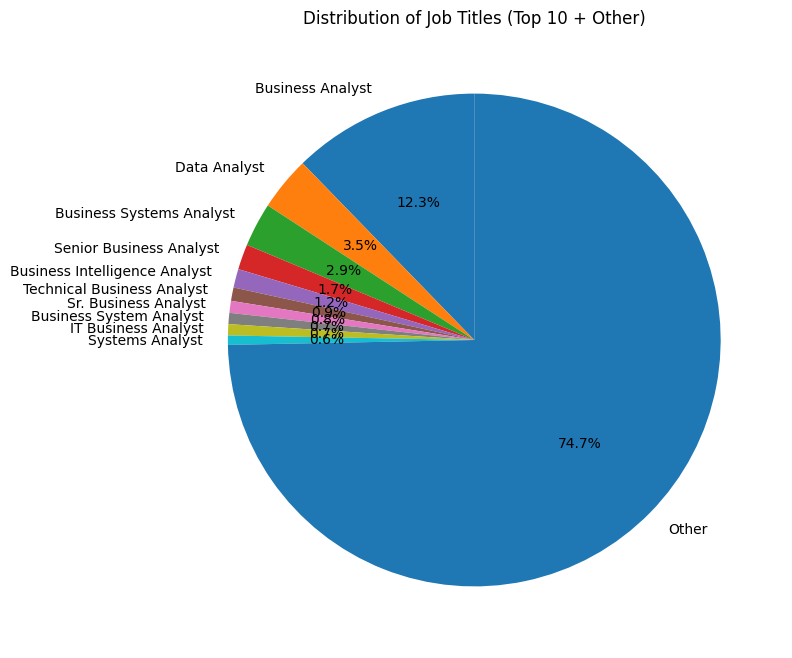

<local-user-path>\AppData\Local\Temp\ipykernel_13200\3719270684.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Salary_Range'] = pd.cut(df_clean['Salary Estimate'], bins=8)
<local-user-path>\AppData\Local\Temp\ipykernel_13200\3719270684.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  salary_avg = df_clean.groupby('Salary_Range')['Rating'].mean()
<local-user-path>\AppData\Local\Temp\ipykernel_13200\3719270684.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

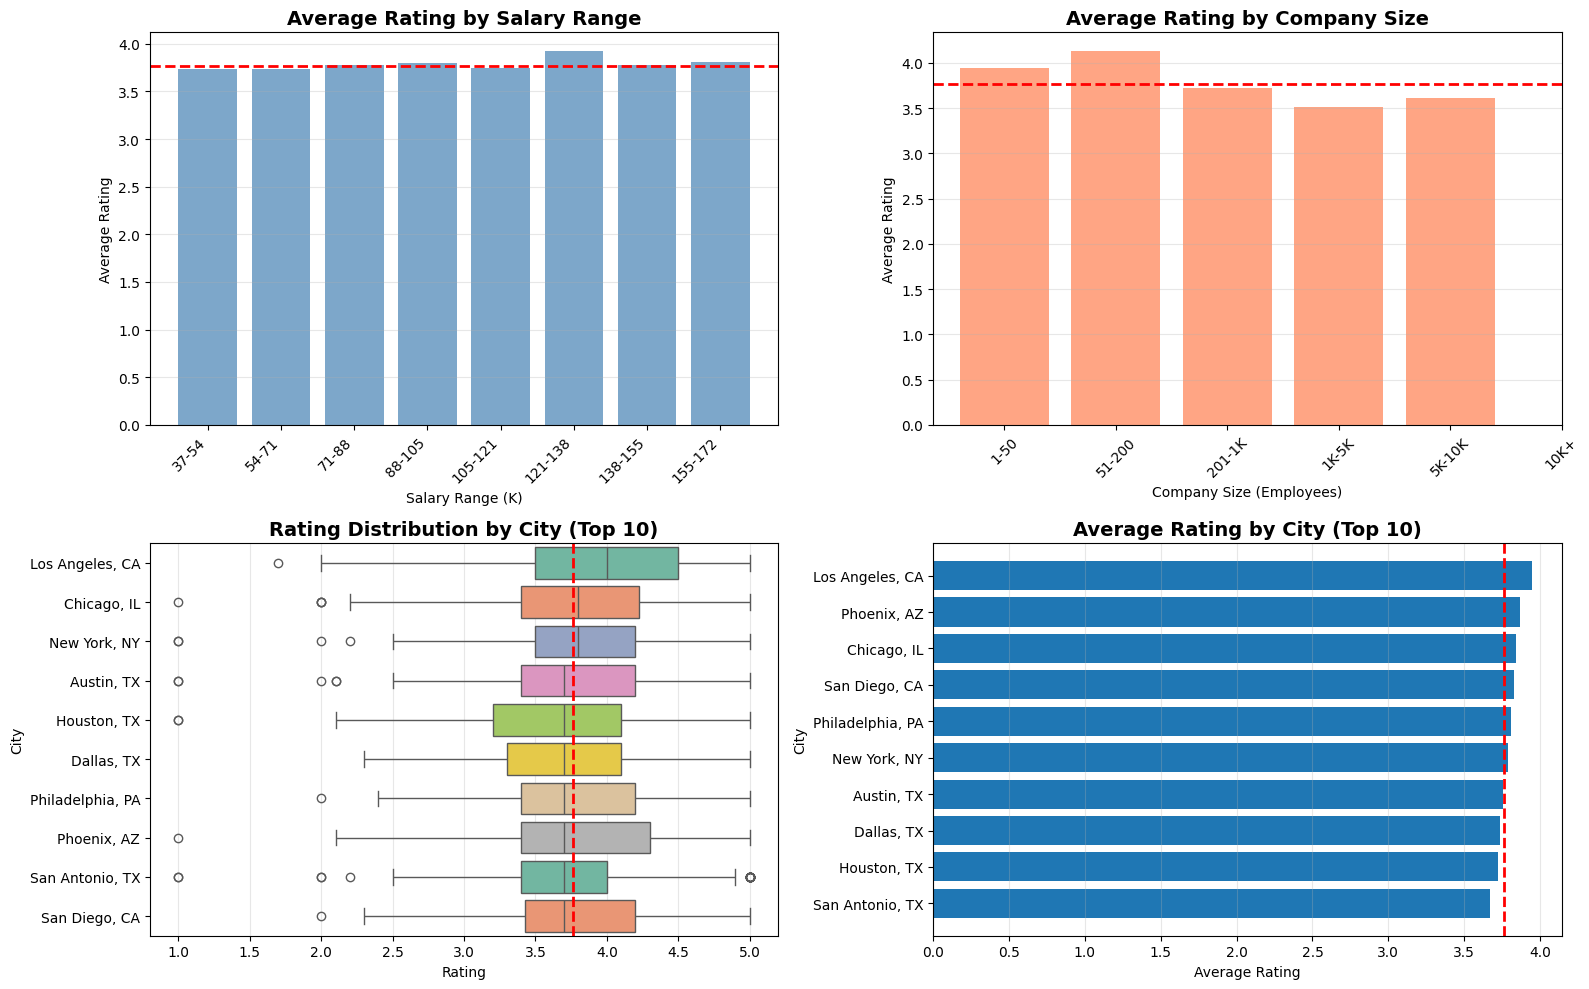


1. correlation (Pearson):

Rating vs Salary Estimate:  r = 0.0432,  p-value = 0.01259
Statistically significant correlation

Rating vs Company Size:  r = -0.2070,  p-value = 0.00000
Statistically significant correlation

1. correlation (ANOVA):

Rating vs Location (City):
F-statistic = 1.4142,  p-value = 0.00020
City location affects job ratings


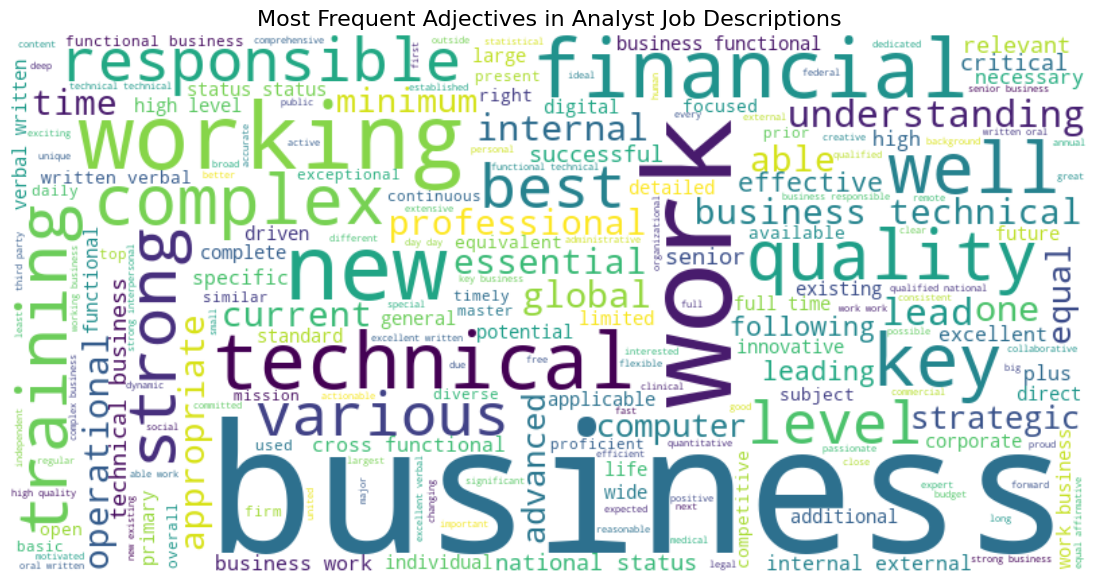

In [14]:
#part1

dataframe3['Job Title'] = label_encoders['Job Title'].inverse_transform(dataframe3['Job Title'])
job_counts = dataframe3['Job Title'].value_counts()
top_jobs = job_counts[:10]
other_sum = job_counts[10:].sum()
job_counts_plot = pd.concat([top_jobs, pd.Series({'Other': other_sum})])

# Plot
plt.figure(figsize=(8,8))
plt.pie(job_counts_plot, labels=job_counts_plot.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Job Titles (Top 10 + Other)')
plt.show()

#part2

dataframe3['City_Name'] = label_encoders['Location'].inverse_transform(dataframe3['Location'])

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
df_clean = dataframe3.dropna(subset=['Salary Estimate', 'Rating'])
df_clean['Salary_Range'] = pd.cut(df_clean['Salary Estimate'], bins=8)
salary_avg = df_clean.groupby('Salary_Range')['Rating'].mean()

axes[0, 0].bar(range(len(salary_avg)), salary_avg.values, color='steelblue', alpha=0.7)
axes[0, 0].set_title('Average Rating by Salary Range', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Salary Range (K)')
axes[0, 0].set_ylabel('Average Rating')
axes[0, 0].set_xticks(range(len(salary_avg)))
axes[0, 0].set_xticklabels([f'{int(i.left)}-{int(i.right)}' for i in salary_avg.index],rotation=45, ha='right')
axes[0, 0].axhline(y=df_clean['Rating'].mean(), color='red', linestyle='--', linewidth=2)
axes[0, 0].grid(True, alpha=0.3, axis='y')

df_size = dataframe3.dropna(subset=['Company_Size_Numeric', 'Rating'])
df_size['Size_Category'] = pd.cut(df_size['Company_Size_Numeric'],  bins=[0, 50, 200, 1000, 5000, 10000, 50000],labels=['1-50', '51-200', '201-1K', '1K-5K', '5K-10K', '10K+'])
size_avg = df_size.groupby('Size_Category')['Rating'].mean()

axes[0, 1].bar(range(len(size_avg)), size_avg.values, color='coral', alpha=0.7)
axes[0, 1].set_title('Average Rating by Company Size', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Company Size (Employees)')
axes[0, 1].set_ylabel('Average Rating')
axes[0, 1].set_xticks(range(len(size_avg)))
axes[0, 1].set_xticklabels(size_avg.index, rotation=45)
axes[0, 1].axhline(y=df_size['Rating'].mean(), color='red', linestyle='--', linewidth=2)
axes[0, 1].grid(True, alpha=0.3, axis='y')

top_cities = dataframe3['City_Name'].value_counts().head(10).index
df_city = dataframe3[dataframe3['City_Name'].isin(top_cities)].copy()
city_order = df_city.groupby('City_Name')['Rating'].median().sort_values(ascending=False).index

sns.boxplot(data=df_city, y='City_Name', x='Rating', ax=axes[1, 0], order=city_order, palette='Set2')
axes[1, 0].set_title('Rating Distribution by City (Top 10)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('City')
axes[1, 0].axvline(x=dataframe3['Rating'].mean(), color='red', linestyle='--', linewidth=2)
axes[1, 0].grid(True, alpha=0.3, axis='x')

city_avg = df_city.groupby('City_Name')['Rating'].mean().sort_values(ascending=True)
axes[1, 1].barh(range(len(city_avg)), city_avg.values)
axes[1, 1].set_title('Average Rating by City (Top 10)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Average Rating')
axes[1, 1].set_ylabel('City')
axes[1, 1].set_yticks(range(len(city_avg)))
axes[1, 1].set_yticklabels(city_avg.index)
axes[1, 1].axvline(x=dataframe3['Rating'].mean(), color='red', linestyle='--', linewidth=2)
axes[1, 1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()


#part3

df_corr = dataframe3.dropna(subset=['Rating', 'Salary Estimate', 'Company_Size_Numeric', 'Location'])
corr_salary, p_salary = pearsonr(df_corr['Rating'], df_corr['Salary Estimate'])
corr_size, p_size = pearsonr(df_corr['Rating'], df_corr['Company_Size_Numeric'])

print("\n1. correlation (Pearson):\n")
print(f"Rating vs Salary Estimate:  r = {corr_salary:.4f},  p-value = {p_salary:.5f}")
if p_salary < 0.05:
    print(f"Statistically significant correlation")
else:
    print(f"no reliable correlation")

print(f"\nRating vs Company Size:  r = {corr_size:.4f},  p-value = {p_size:.5f}")
if p_size < 0.05:
    print(f"Statistically significant correlation")
else:
    print(f"no reliable correlation")

# ANOVA
print("\n1. correlation (ANOVA):\n")
print("Rating vs Location (City):")
city_groups = [group['Rating'].values for name, group in df_corr.groupby('Location')]
f_stat, p_city = f_oneway(*city_groups)

print(f"F-statistic = {f_stat:.4f},  p-value = {p_city:.5f}")
if p_city < 0.05:
    print(f"City location affects job ratings")
else:
    print(f"City location does not affect job ratings")


#part5

all_words = []
dataframe3['Job Description'] = label_encoders['Job Description'].inverse_transform(dataframe3['Job Description'])
for w in dataframe3['Job Description'].dropna():
    w = str(w)
    words = re.findall(r'\b[a-zA-Z]+\b', w.lower()) 
    all_words.extend(words)

with open(r'data\Q3\adjectives.txt','r') as file:
    adjectives = set(word.strip().lower() for word in file.readlines())

adj_words = [word for word in all_words if word in adjectives]

text = " ".join(adj_words)
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis',max_words=200).generate(text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequent Adjectives in Analyst Job Descriptions", fontsize=16)
plt.show()

**Explain your approach and assumptions once this section is completed.**

Q1- As the pie chart for job titles shows, the most demanded job (excluding "Others") is Business Analyst.

Q2- The visualizations show that higher salary ranges tend to have higher ratings. Additionally, companies with 51-200 employees receive more ratings. Jobs in Los Angeles, CA had the highest number of ratings among the top 10 cities.

Q3- To find correlations, Pearson correlation was used for Rating vs Salary and Rating vs Company Size since both variables are continuous. Since their p-values were less than   0.05, they are considered statistically correlated. For the categorical variable (City Location) vs continuous variable (Rating), ANOVA was used, which determined that there is a statistically significant relationship between city location and ratings.

Q4- As shown in the figure, higher salary ranges align with or exceed the average rating line, indicating that people rate high-paid jobs more. Based on the Pearson correlation results, there is a positive correlation, suggesting that "Higher salary is associated with greater job satisfaction" (note: correlation does not necessarily imply causation).

Q5- The job description column was extracted and compared against adjectives from the "adjectives" file. Matching adjectives were added to a list, which was then used to generate the word cloud shown above.

Q6- The main capabilities one must possess to hold an Analyst position in the US are: 1-Responsible 2-Technical 3-Strategic 4-Senior 5-passionate 

# 4. Covid in the US
In this question, you are required to reproduce the graphs shown in a real journalistic article. After all, reproducibility is an important part of professional journalism as well as data science. Also, a great deal of a data scientist's work is to communicate data in a way that anyone with any level of expertise in the field would understand.

You should reproduce the 4 graphs shown in <a href="https://projects.fivethirtyeight.com/coronavirus-polls/"> this article</a>. The data is openly accessible through <a href="https://github.com/fivethirtyeight/covid-19-polls/"> FiveThirtyEight's github</a>. Nevertheless, both the data and the article are available in `data` folder in case of unstable internet connections!

*Note: Your graphs don't have to be as interactive or detailed as the ones on the website. Only showing the averages, some (not all) data points with light color, legends, titles, x values, and y values are necessary.*

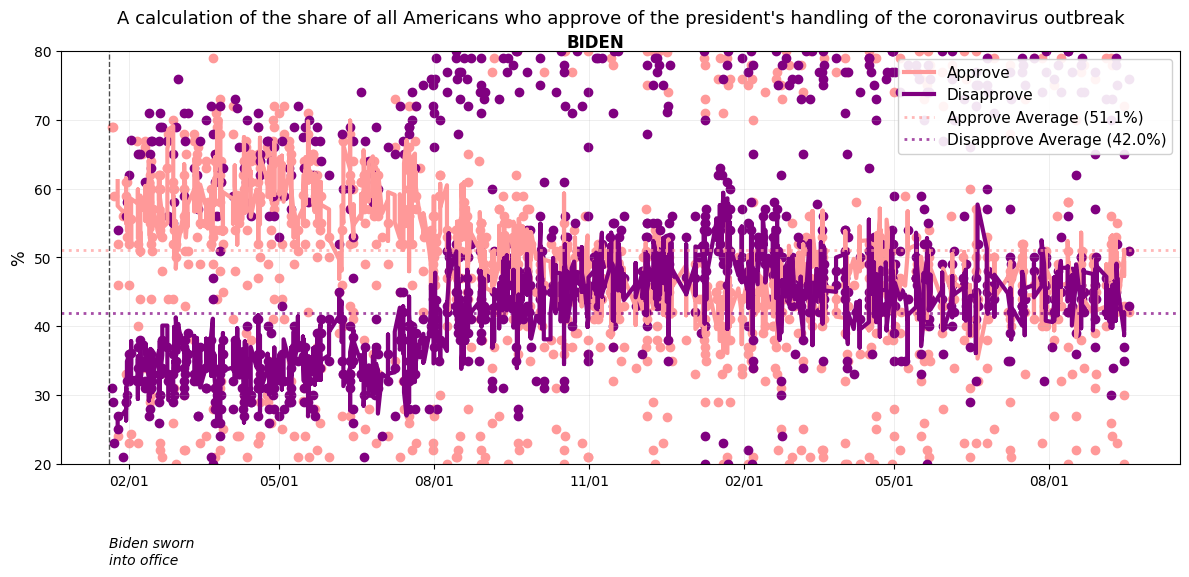

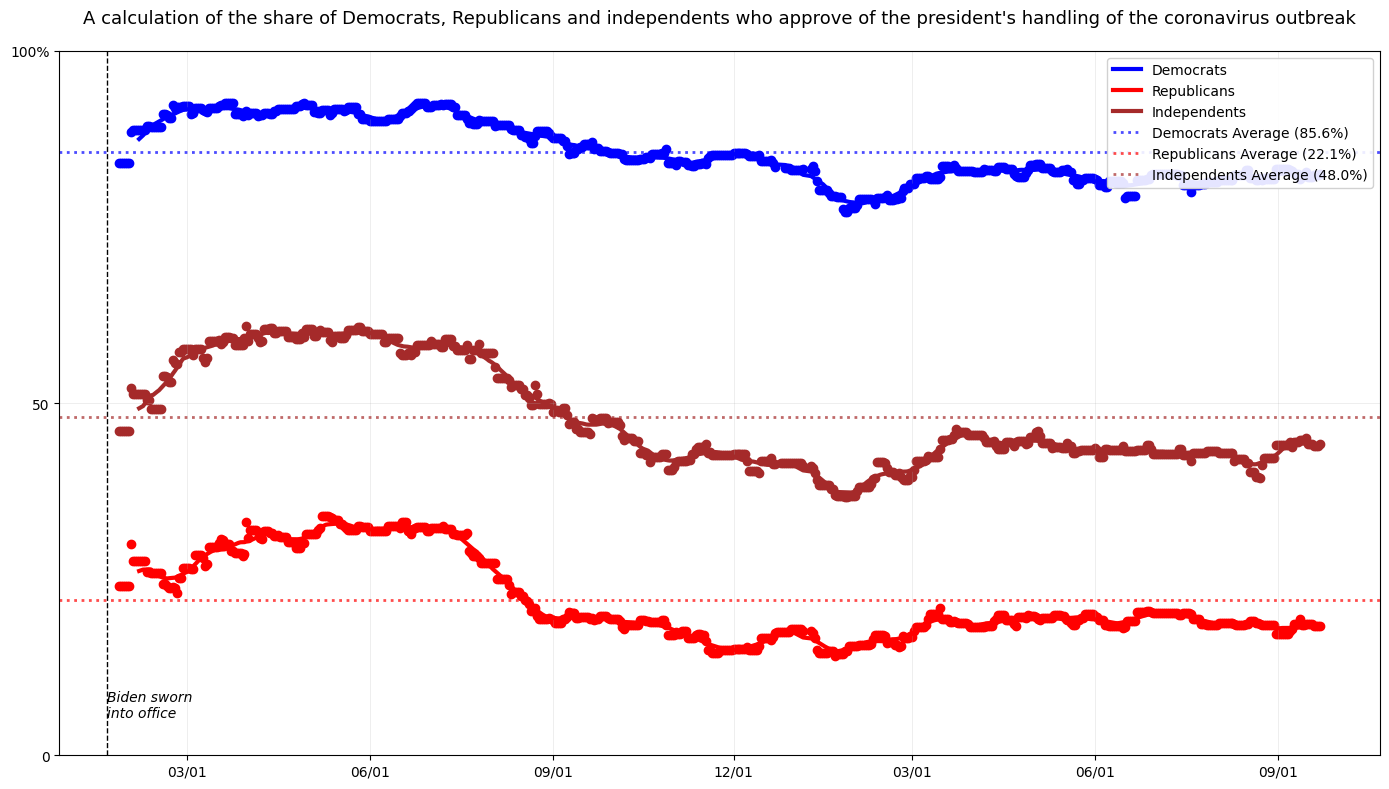

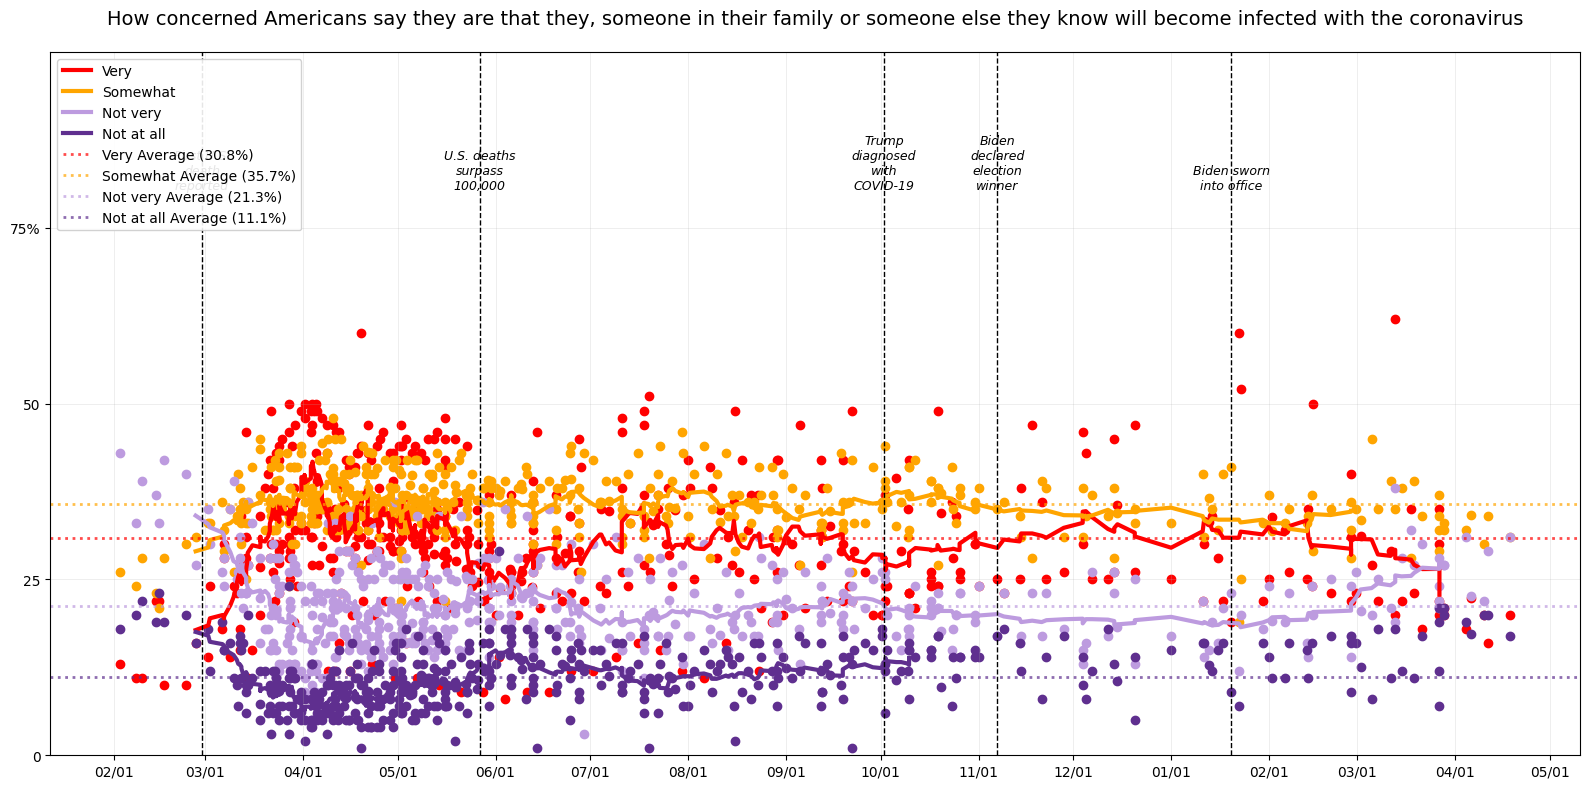

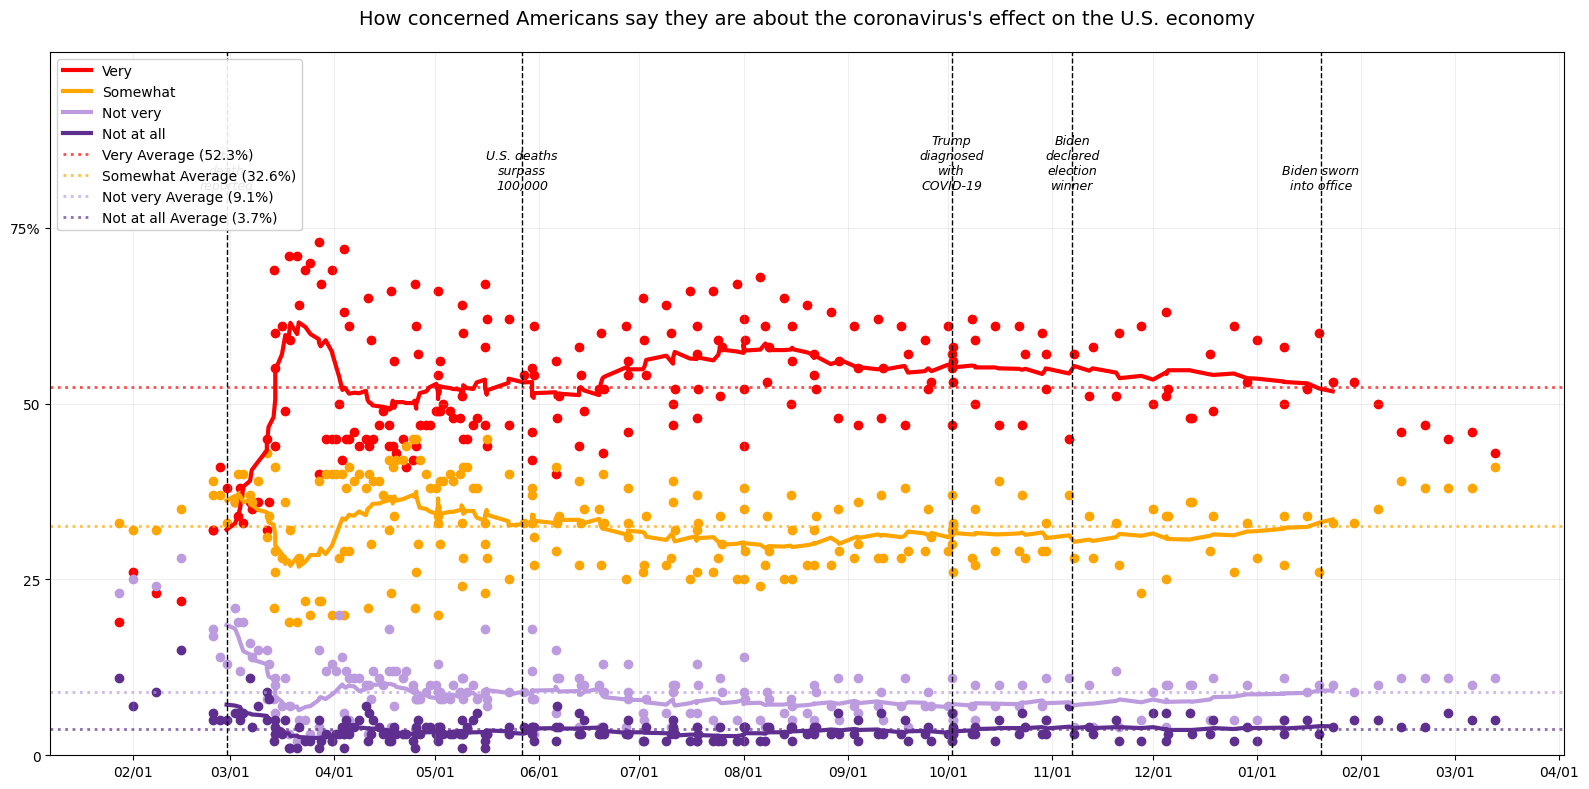

In [15]:
#graph 1 for Biden
df_polls = pd.read_csv(r'data\Q4\covid\covid-19-polls-master\covid_approval_polls.csv')

df_polls['start_date'] = pd.to_datetime(df_polls['start_date'])
df_polls['end_date'] = pd.to_datetime(df_polls['end_date'])
df_polls['poll_date'] = df_polls['start_date'] + (df_polls['end_date'] - df_polls['start_date']) / 2

# separate Biden and Trump 
biden_data = df_polls[df_polls['subject'] == 'Biden'].copy()  
trump_data = df_polls[df_polls['subject'] == 'Trump'].copy() 
biden_data = biden_data.sort_values('poll_date')
trump_data = trump_data.sort_values('poll_date')

#Plot
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(biden_data['poll_date'], biden_data['approve'],color='#ff9999')
ax.scatter(biden_data['poll_date'], biden_data['disapprove'], color= "purple")
biden_data['approve_2'] = biden_data['approve'].rolling(window=10, center=True).mean()
biden_data['disapprove_2'] = biden_data['disapprove'].rolling(window=10, center=True).mean()
ax.plot(biden_data['poll_date'], biden_data['approve_2'], color='#ff9999', linewidth=3, label='Approve')
ax.plot(biden_data['poll_date'], biden_data['disapprove_2'], color='purple', linewidth=3, label='Disapprove')

avg_approve = biden_data['approve'].mean()
avg_disapprove = biden_data['disapprove'].mean()
ax.axhline(avg_approve, color='#ff9999', linestyle=':', linewidth=2, label=f'Approve Average ({avg_approve:.1f}%)', alpha=0.7)
ax.axhline(avg_disapprove, color='purple', linestyle=':', linewidth=2, label=f'Disapprove Average ({avg_disapprove:.1f}%)', alpha=0.7)
inauguration_date = pd.to_datetime('2021-01-20')
ax.axvline(inauguration_date, color='black', linestyle='--', linewidth=1, alpha=0.7)
ax.text(inauguration_date, 5, 'Biden sworn\ninto office', ha='left', va='bottom', fontsize=10, style='italic')

ax.set_ylabel('%', fontsize=12)
ax.set_title("A calculation of the share of all Americans who approve of the president's handling of the coronavirus outbreak",fontsize=13, pad=20)
ax.set_ylim(20, 80)
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
fig.text(0.5, 0.92, 'BIDEN', ha='center', va='center', fontsize=12, color='black', fontweight='bold')
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.tight_layout()
plt.show()

#graph2 Biden

df_party = pd.read_csv(r'data\Q4\covid\covid-19-polls-master\covid_approval_toplines.csv')
df_party['modeldate'] = pd.to_datetime(df_party['modeldate'])
biden_party_data = df_party[df_party['subject'] == 'Biden'].copy()
biden_party_data = biden_party_data.sort_values('modeldate')
democrats = biden_party_data[biden_party_data['party'] == 'D'].copy()
republicans = biden_party_data[biden_party_data['party'] == 'R'].copy()
independents = biden_party_data[biden_party_data['party'] == 'I'].copy()

#plot
fig, ax = plt.subplots(figsize=(14, 8))

colors = {
    'D': 'blue',      #Democrats
    'R': 'red',      #Republicans
    'I': 'brown'       #Independents
}

ax.scatter(democrats['modeldate'], democrats['approve_estimate'], color=colors['D'])
ax.scatter(republicans['modeldate'], republicans['approve_estimate'], color=colors['R'])
ax.scatter(independents['modeldate'], independents['approve_estimate'], color=colors['I'])
democrats['approve_2'] = democrats['approve_estimate'].rolling(window=20, center=True).mean()
republicans['approve_2'] = republicans['approve_estimate'].rolling(window=20, center=True).mean()
independents['approve_2'] = independents['approve_estimate'].rolling(window=20, center=True).mean()

ax.plot(democrats['modeldate'], democrats['approve_2'], color=colors['D'], linewidth=3, label='Democrats')
ax.plot(republicans['modeldate'], republicans['approve_2'], color=colors['R'], linewidth=3, label='Republicans')
ax.plot(independents['modeldate'], independents['approve_2'], color=colors['I'], linewidth=3, label='Independents')

avg_dem = democrats['approve_estimate'].mean()
avg_rep = republicans['approve_estimate'].mean()
avg_ind = independents['approve_estimate'].mean()
ax.axhline(avg_dem, color=colors['D'], linestyle=':', linewidth=2, label=f'Democrats Average ({avg_dem:.1f}%)', alpha=0.7)
ax.axhline(avg_rep, color=colors['R'], linestyle=':', linewidth=2, label=f'Republicans Average ({avg_rep:.1f}%)', alpha=0.7)
ax.axhline(avg_ind, color=colors['I'], linestyle=':', linewidth=2, label=f'Independents Average ({avg_ind:.1f}%)', alpha=0.7)
inauguration_date = pd.to_datetime('2021-01-20')
ax.axvline(inauguration_date, color='black', linestyle='--', linewidth=1)
ax.text(inauguration_date, 5, 'Biden sworn\ninto office', ha='left', va='bottom', style='italic')

ax.set_title("A calculation of the share of Democrats, Republicans and independents who approve of the president's handling of the coronavirus outbreak",fontsize=13, pad=20)
ax.set_ylim(0, 100)
ax.set_yticks([0, 50, 100])
ax.set_yticklabels(['0', '50', '100%'])
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.legend(loc='upper right', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

#graph3 Biden

df_concern_Infected = pd.read_csv(r'data\Q4\covid\covid-19-polls-master\covid_concern_polls.csv')
df_concern_Infected['start_date'] = pd.to_datetime(df_concern_Infected['start_date'])
df_concern_Infected['end_date'] = pd.to_datetime(df_concern_Infected['end_date'])
df_concern_Infected['poll_date'] = df_concern_Infected['start_date'] + (df_concern_Infected['end_date'] - df_concern_Infected['start_date']) / 2
Infected_data = df_concern_Infected[df_concern_Infected['subject'] == 'concern-infected'].copy()
Infected_data = Infected_data.sort_values('poll_date')

#plot
fig, ax = plt.subplots(figsize=(16, 8))

colors = { 'very': 'red', 'somewhat': 'orange', 'not_very': "#bd9bdf", 'not_at_all': "#5f2f8f"}

concern_levels = ['very', 'somewhat', 'not_very', 'not_at_all']
for level in concern_levels:
    ax.scatter(Infected_data['poll_date'], Infected_data[level], color=colors[level])

for level in concern_levels:
    Infected_data[f'{level}_2'] = Infected_data[level].rolling(window=15, center=True).mean()

ax.plot(Infected_data['poll_date'], Infected_data['very_2'],  color=colors['very'], linewidth=3, label='Very')
ax.plot(Infected_data['poll_date'], Infected_data['somewhat_2'], color=colors['somewhat'], linewidth=3, label='Somewhat')
ax.plot(Infected_data['poll_date'], Infected_data['not_very_2'], color=colors['not_very'], linewidth=3, label='Not very')
ax.plot(Infected_data['poll_date'], Infected_data['not_at_all_2'], color=colors['not_at_all'], linewidth=3, label='Not at all')

avg_very = Infected_data['very'].mean()
avg_somewhat = Infected_data['somewhat'].mean()
avg_not_very = Infected_data['not_very'].mean()
avg_not_at_all = Infected_data['not_at_all'].mean()

ax.axhline(avg_very, color=colors['very'], linestyle=':', linewidth=2, label=f'Very Average ({avg_very:.1f}%)', alpha=0.7)
ax.axhline(avg_somewhat, color=colors['somewhat'], linestyle=':', linewidth=2, label=f'Somewhat Average ({avg_somewhat:.1f}%)', alpha=0.7)
ax.axhline(avg_not_very, color=colors['not_very'], linestyle=':', linewidth=2, label=f'Not very Average ({avg_not_very:.1f}%)', alpha=0.7)
ax.axhline(avg_not_at_all, color=colors['not_at_all'], linestyle=':', linewidth=2, label=f'Not at all Average ({avg_not_at_all:.1f}%)', alpha=0.7)

#Important events
events = {
    '2020-02-29': ('First U.S.\ndeath\nreported', 80),
    '2020-05-27': ('U.S. deaths\nsurpass\n100,000', 80),
    '2020-10-02': ('Trump\ndiagnosed\nwith\nCOVID-19', 80),
    '2020-11-07': ('Biden\ndeclared\nelection\nwinner', 80),
    '2021-01-20': ('Biden sworn\ninto office', 80)
}

for date_str, (label, y_pos) in events.items():
    date = pd.to_datetime(date_str)
    ax.axvline(date, color='black', linestyle='--', linewidth=1)
    ax.text(date, y_pos, label, ha='center', va='bottom',  fontsize=9, style='italic')


ax.set_title("How concerned Americans say they are that they, someone in their family or someone else they know will become infected with the coronavirus",fontsize=14, pad=20)

ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75])
ax.set_yticklabels(['0', '25', '50', '75%'])
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

#graph4 Biden

df_concern_economy = pd.read_csv(r'data\Q4\covid\covid-19-polls-master\covid_concern_polls.csv')
df_concern_economy['start_date'] = pd.to_datetime(df_concern_economy['start_date'])
df_concern_economy['end_date'] = pd.to_datetime(df_concern_economy['end_date'])
df_concern_economy['poll_date'] = df_concern_economy['start_date'] + (df_concern_economy['end_date'] - df_concern_economy['start_date']) / 2
economy_data = df_concern_economy[df_concern_economy['subject'] == 'concern-economy'].copy()
economy_data = economy_data.sort_values('poll_date')

#plot
fig, ax = plt.subplots(figsize=(16, 8))

colors = { 'very': 'red', 'somewhat': 'orange', 'not_very': "#bd9bdf", 'not_at_all': "#5f2f8f"}

concern_levels = ['very', 'somewhat', 'not_very', 'not_at_all']
for level in concern_levels:
    ax.scatter(economy_data['poll_date'], economy_data[level], color=colors[level])

for level in concern_levels:
    economy_data[f'{level}_2'] = economy_data[level].rolling(window=15, center=True).mean()

ax.plot(economy_data['poll_date'], economy_data['very_2'],  color=colors['very'], linewidth=3, label='Very')
ax.plot(economy_data['poll_date'], economy_data['somewhat_2'], color=colors['somewhat'], linewidth=3, label='Somewhat')
ax.plot(economy_data['poll_date'], economy_data['not_very_2'], color=colors['not_very'], linewidth=3, label='Not very')
ax.plot(economy_data['poll_date'], economy_data['not_at_all_2'], color=colors['not_at_all'], linewidth=3, label='Not at all')


avg_very = economy_data['very'].mean()
avg_somewhat = economy_data['somewhat'].mean()
avg_not_very = economy_data['not_very'].mean()
avg_not_at_all = economy_data['not_at_all'].mean()

ax.axhline(avg_very, color=colors['very'], linestyle=':', linewidth=2, label=f'Very Average ({avg_very:.1f}%)', alpha=0.7)
ax.axhline(avg_somewhat, color=colors['somewhat'], linestyle=':', linewidth=2, label=f'Somewhat Average ({avg_somewhat:.1f}%)', alpha=0.7)
ax.axhline(avg_not_very, color=colors['not_very'], linestyle=':', linewidth=2, label=f'Not very Average ({avg_not_very:.1f}%)', alpha=0.7)
ax.axhline(avg_not_at_all, color=colors['not_at_all'], linestyle=':', linewidth=2, label=f'Not at all Average ({avg_not_at_all:.1f}%)', alpha=0.7)

#Important events
events = {
    '2020-02-29': ('First U.S.\ndeath\nreported', 80),
    '2020-05-27': ('U.S. deaths\nsurpass\n100,000', 80),
    '2020-10-02': ('Trump\ndiagnosed\nwith\nCOVID-19', 80),
    '2020-11-07': ('Biden\ndeclared\nelection\nwinner', 80),
    '2021-01-20': ('Biden sworn\ninto office', 80)
}

for date_str, (label, y_pos) in events.items():
    date = pd.to_datetime(date_str)
    ax.axvline(date, color='black', linestyle='--', linewidth=1)
    ax.text(date, y_pos, label, ha='center', va='bottom',  fontsize=9, style='italic')


ax.set_title("How concerned Americans say they are about the coronavirus's effect on the U.S. economy",fontsize=14, pad=20)

ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75])
ax.set_yticklabels(['0', '25', '50', '75%'])
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()



**Explain your approach and assumptions once this section is completed.**

The first graph shows the calculation of the share of all Americans who approved of Biden's handling of the coronavirus outbreak. As it's shown, the average of people who approved is slightly more than the average of those who disapproved. Also, as time passes, we see a reduction in the approved value and an increment in the disapproved value.

The second graph shows the calculation of Democrats, Republicans, and Independents who approved of Biden's handling of the corona outbreak. As shown in the figure, Democrats are the most supportive and Republicans are the least, and the Independents stand somewhere in the middle.

The third graph shows how concerned Americans are about being infected with coronavirus. It generally shows a trend that people tend to be concerned about being infected, but as time passed, the percentage of people being "very" concerned decreased and they moved toward being "somewhat" worried at the end, which has the highest average too.

The fourth graph shows how concerned Americans are about the effect of corona on the country's economy. It shows that the average of people being "very" concerned has stayed high throughout the pandemic and has decreased a bit since Biden was sworn into office.

*All the above graphs are based on the values extracted for President Biden.*

## 5. Book store data web scraping

Use BeautifulSoup to scrape the data from [this site](https://books.toscrape.com/). It contains bookstore data. 

1. Scrape books’ titles, prices, ratings, and categories from the first page of each category on the site.

2. Store the data in a Pandas DataFrame and perform cleaning (e.g., converting ratings from words to numbers).

3. Visualize key insights:

    Distribution of book prices by category (boxplots).

    Average rating per category (bar chart).

    Number of books scraped per category (bar chart).

4. Write the scraped dataset to a CSV file for further study.

                                               Title  Price  Rating Category
0                            It's Only the Himalayas  45.17       2   Travel
1  Full Moon over Noahâs Ark: An Odyssey to Mou...  49.43       4   Travel
2  See America: A Celebration of Our National Par...  48.87       3   Travel
3  Vagabonding: An Uncommon Guide to the Art of L...  36.94       2   Travel
4                               Under the Tuscan Sun  37.33       3   Travel


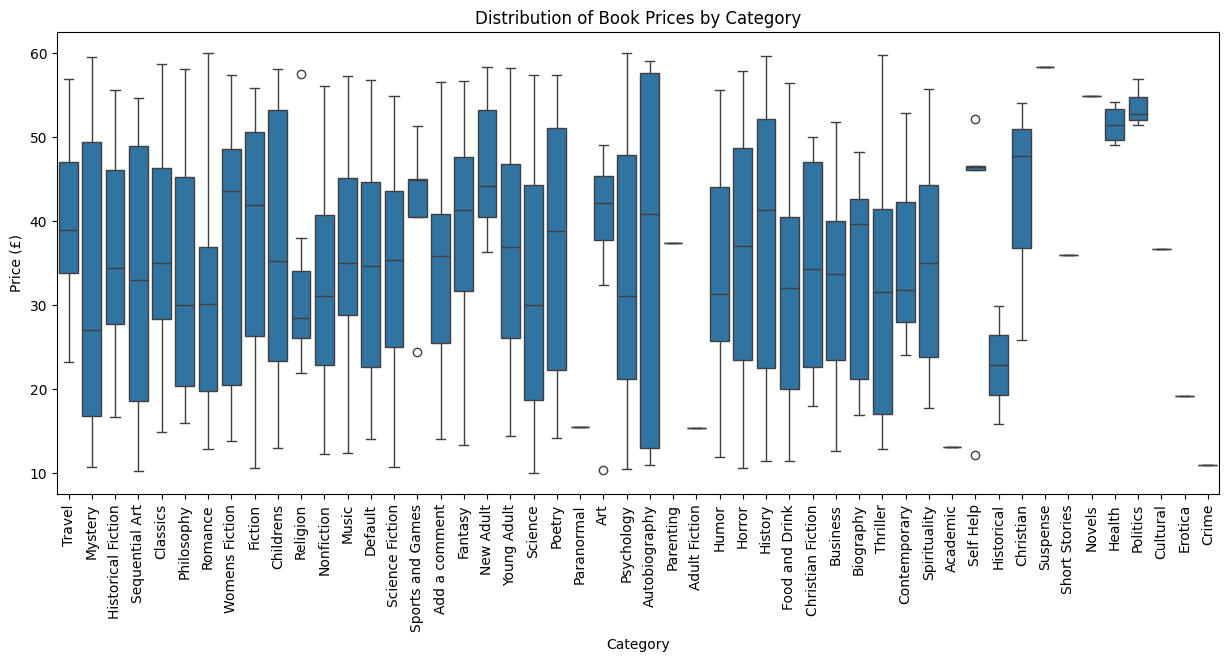

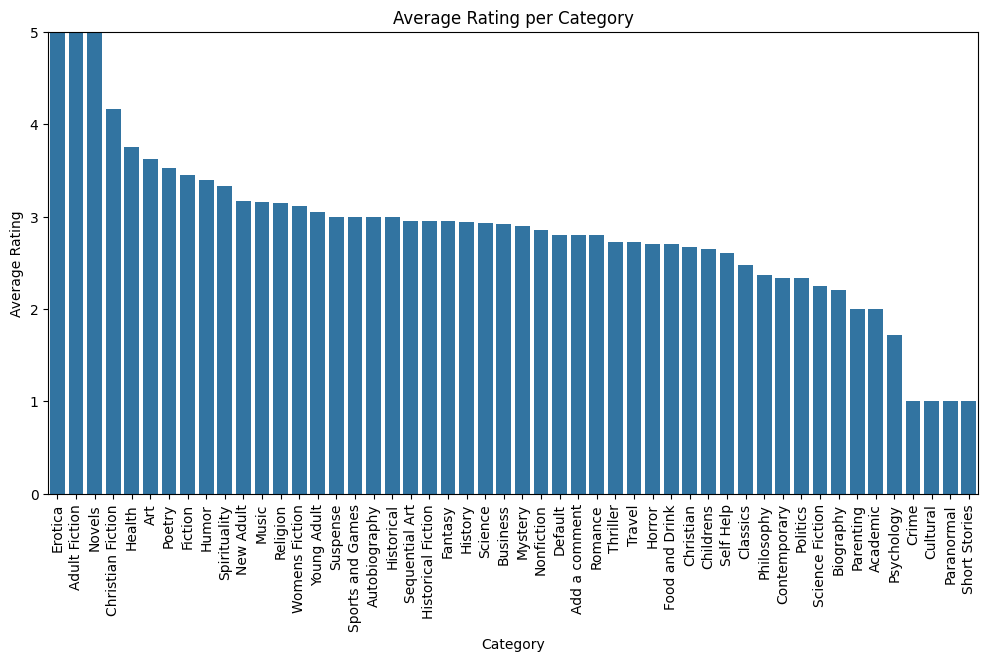

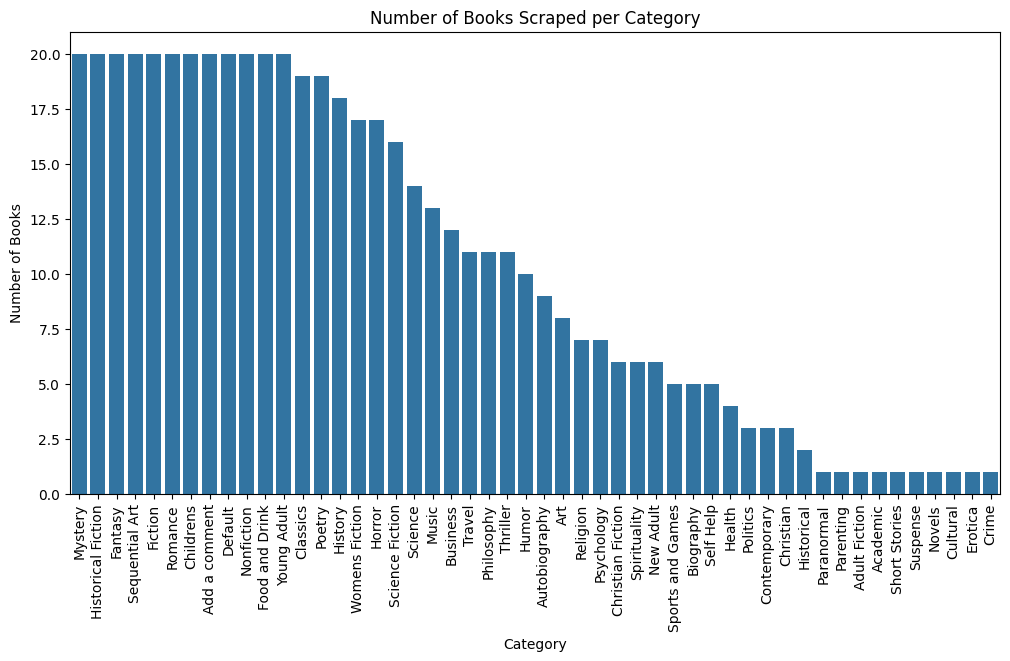

In [3]:
#Part 1 and Part2

base_url = "https://books.toscrape.com/"
response = requests.get(base_url)
soup = BeautifulSoup(response.text, 'html.parser')
categories = soup.find('ul', class_='nav-list').find('ul').find_all('a')
category_links = {cat.get_text(strip=True): base_url + cat['href'] for cat in categories}

rating_list= {'One': 1,'Two': 2,'Three': 3,'Four': 4,'Five': 5}
data = []

for category, link in category_links.items():
    response = requests.get(link)
    soup = BeautifulSoup(response.text, 'html.parser')
    books = soup.find_all('article', class_='product_pod')
    for book in books:
        title = book.h3.a['title']
        price_t = book.find('p', class_='price_color').text.strip().lstrip('£')
        price = float(price_t.replace('£', '').replace('Â', ''))
        rating_class = book.find('p', class_='star-rating')['class'][1] 
        rating = rating_list.get(rating_class, 0)
        data.append({'Title': title,'Price': float(price),'Rating': rating,'Category': category})

df = pd.DataFrame(data)
print(df.head())

#Part3

plt.figure(figsize=(15, 6))
sns.boxplot(x='Category', y='Price', data=df)
plt.xticks(rotation=90)
plt.title('Distribution of Book Prices by Category')
plt.ylabel('Price (£)')
plt.xlabel('Category')
plt.show()


avg_rating = df.groupby('Category')['Rating'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_rating.index, y=avg_rating.values)
plt.xticks(rotation=90)
plt.title('Average Rating per Category')
plt.ylabel('Average Rating')
plt.xlabel('Category')
plt.ylim(0, 5)
plt.show()


book_counts = df['Category'].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(x=book_counts.index, y=book_counts.values)
plt.xticks(rotation=90)
plt.title('Number of Books Scraped per Category')
plt.ylabel('Number of Books')
plt.xlabel('Category')
plt.show()

#Part4
# Save the DataFrame to a CSV file
df.to_csv('books_scraped.csv', index=False)

## 6. Class War in Titanic (Bonus)

Use pandas to import the data file `Data/titanic.xls`. It contains data on all the passengers that travelled on the Titanic.

**Run the following cell for a brief description about the dataset**

In [19]:
from IPython.core.display import HTML
DATA_FOLDER = 'data\Q6'
HTML(filename=DATA_FOLDER+'/titanic.html')
import os

df_titanic = pd.read_excel(r'data\Q6\titanic.xls')


For each of the following questions state clearly your assumptions and discuss your findings:
1. Describe the *type* and the *value range* of each attribute. Indicate and transform the attributes that can be `Categorical`.  
 
2. Plot histograms for the *travel class*, *embarkation port*, *sex* and *age* attributes. For the latter one, use *discrete decade intervals*. 
3. Calculate the proportion of passengers by *cabin floor*. Present your results in a *pie chart*.
4. For each *travel class*, calculate the proportion of the passengers that survived. Present your results in *pie charts*.
5. Calculate the proportion of the passengers that survived by *travel class* and *sex*. Present your results in *a single histogram*.
6. Create 2 equally populated *age categories* and calculate survival proportions by *age category*, *travel class* and *sex*. Present your results in a `DataFrame` with unique index.

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745
unique,NaN,NaN,1307,2,NaN,NaN,NaN,939,NaN,186,3,28,NaN,369
top,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY"
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN



Categorical Columns (7):
  - name
  - sex
  - ticket
  - cabin
  - embarked
  - boat
  - home.dest

name:
  Original values: 1307

sex:
  Original values: 2
    0 = 'female'
    1 = 'male'

ticket:
  Original values: 929

cabin:
  Original values: 187

embarked:
  Original values: 4
    0 = 'C'
    1 = 'Q'
    2 = 'S'
    3 = 'nan'

boat:
  Original values: 28

home.dest:
  Original values: 370


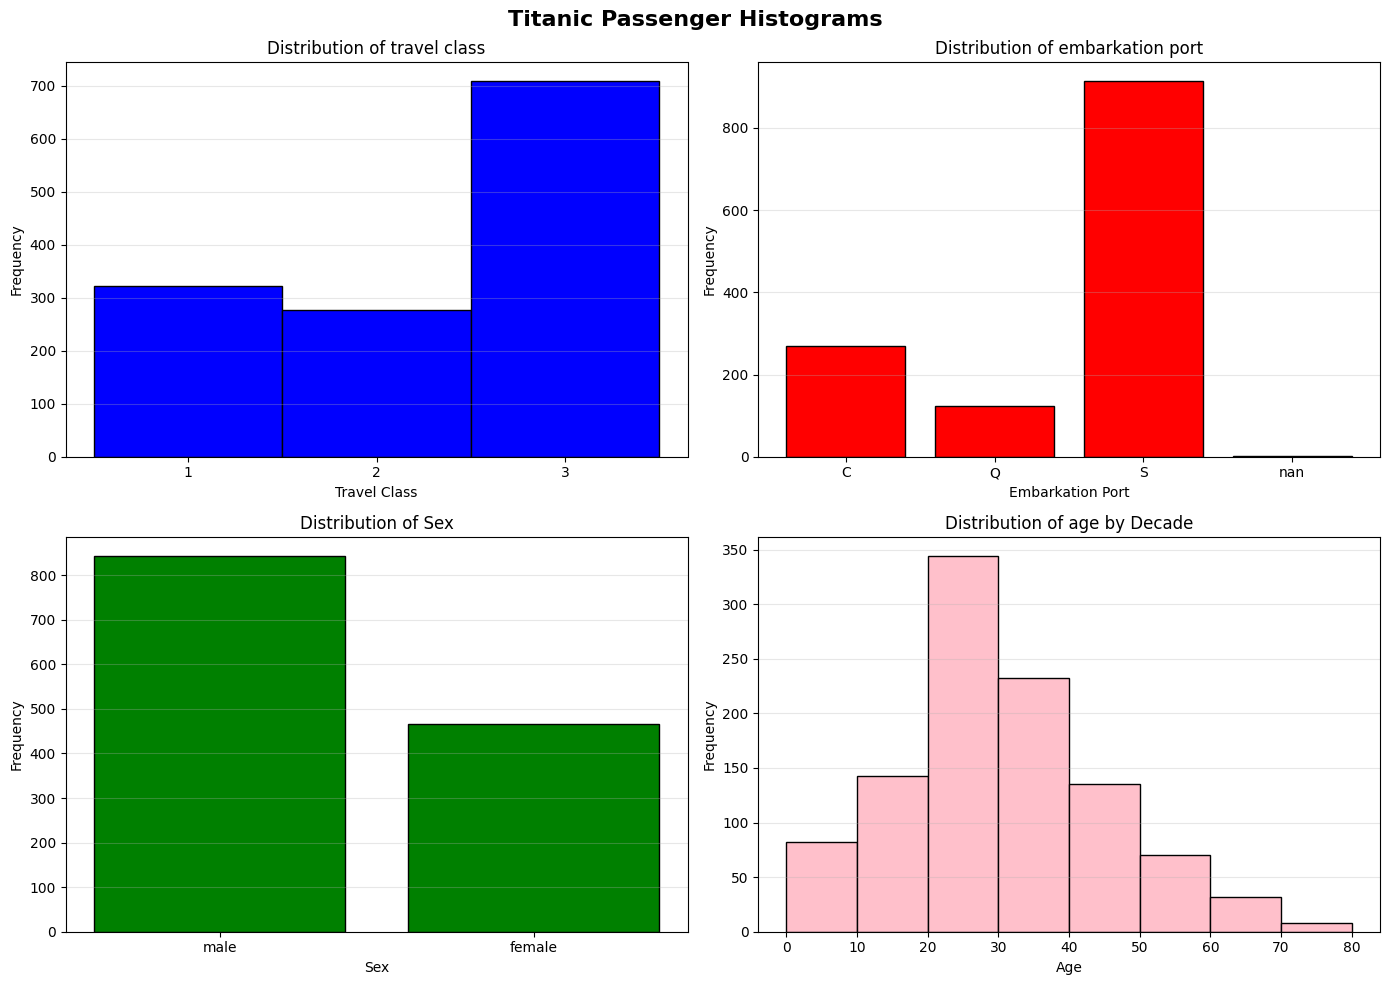

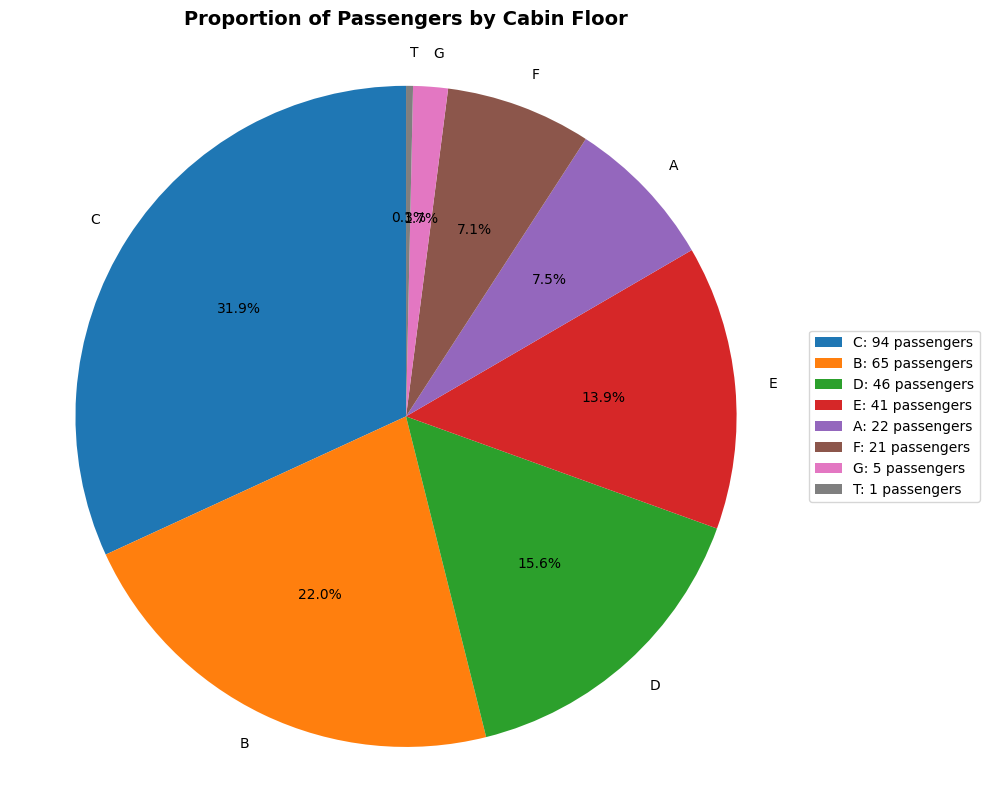

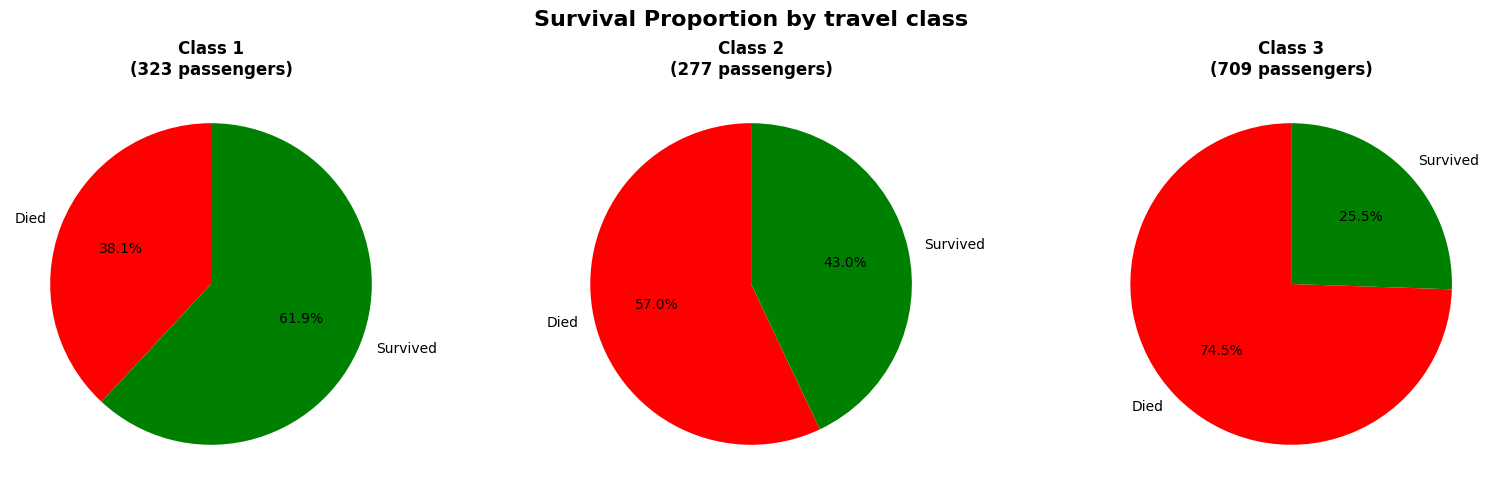

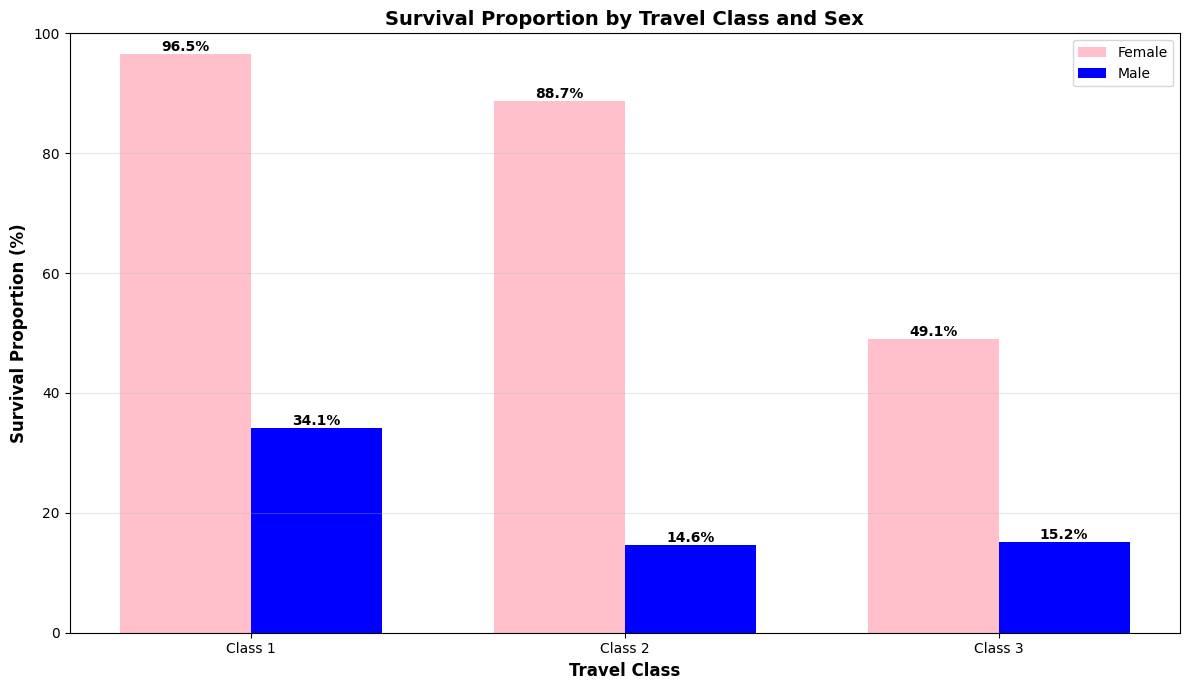

                                  Total  Survived  Survival Rate (%)
Age Category Travel Class Sex                                       
Young        1            female     40        38              95.00
                          male       28        15              53.57
             2            female     51        46              90.20
                          male       68        16              23.53
             3            female    106        56              52.83
                          male      211        41              19.43
Old          1            female    104       101              97.12
                          male      151        46              30.46
             2            female     55        48              87.27
                          male      103         9               8.74
             3            female    110        50              45.45
                          male      282        34              12.06


In [20]:
#part1

display(df_titanic.describe(include='all'))

categorical_columns = df_titanic.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical Columns ({len(categorical_columns)}):")
for col in categorical_columns:
    print(f"  - {col}")

#Label encoding

label_encoders = {}

for col in categorical_columns:
    if col in df_titanic.columns:
        df_titanic[col] = df_titanic[col].astype(str)
        le = LabelEncoder()
        df_titanic[col] = le.fit_transform(df_titanic[col])
        label_encoders[col] = le
        
        print(f"\n{col}:")
        print(f"  Original values: {df_titanic[col].nunique()}")
        if df_titanic[col].nunique() <= 20:
            for i, category in enumerate(le.classes_):
                print(f"    {i} = '{category}'")

#part2 

df_copy = df_titanic.copy()

for col in ['pclass', 'embarked', 'sex']:
    if col in label_encoders:
        df_copy[col] = label_encoders[col].inverse_transform(df_titanic[col])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Titanic Passenger Histograms', fontsize=16, fontweight='bold')

# Travel Class
axes[0, 0].hist(df_copy['pclass'], bins=np.arange(0.5, 4.5, 1), edgecolor='black', color='blue')
axes[0, 0].set_xlabel('Travel Class')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of travel class')
axes[0, 0].set_xticks([1, 2, 3])
axes[0, 0].grid(axis='y', alpha=0.3)

# Embarkation Port
embark_counts = df_copy['embarked'].value_counts().sort_index()
axes[0, 1].bar(embark_counts.index, embark_counts.values, edgecolor='black', color='red')
axes[0, 1].set_xlabel('Embarkation Port')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of embarkation port')
axes[0, 1].grid(axis='y', alpha=0.3)

# Sex
sex_counts = df_copy['sex'].value_counts()
axes[1, 0].bar(sex_counts.index, sex_counts.values, edgecolor='black', color='green')
axes[1, 0].set_xlabel('Sex')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Sex')
axes[1, 0].grid(axis='y', alpha=0.3)

# Age
age_bins = np.arange(0, df_copy['age'].max() + 10, 10)
axes[1, 1].hist(df_copy['age'].dropna(), bins=age_bins,edgecolor='black', color='pink')
axes[1, 1].set_xlabel('Age')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Distribution of age by Decade')
axes[1, 1].set_xticks(age_bins)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

#part3

df_copy2 = df_titanic.copy()

df_copy2['cabin'] = label_encoders['cabin'].inverse_transform(df_titanic['cabin'])

df_copy2['cabin_floor'] = df_copy2['cabin'].astype(str).str[0]

cabin_floors = df_copy2[df_copy2['cabin_floor'] != 'n']['cabin_floor']
floor_counts = cabin_floors.value_counts()
floor_proportions = floor_counts / floor_counts.sum() * 100

# pie chart
plt.figure(figsize=(10, 8))
colors = plt.cm.Set3(range(len(floor_counts)))
plt.pie(floor_counts, labels=floor_counts.index, autopct='%1.1f%%', startangle=90)

plt.title('Proportion of Passengers by Cabin Floor', fontsize=14, fontweight='bold', pad=20)

legend_labels = [f'{floor}: {count} passengers' for floor, count in floor_counts.items()]
plt.legend(legend_labels, loc='center left', bbox_to_anchor=(1, 0.5))

plt.axis('equal')
plt.tight_layout()
plt.show()

#part4

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Survival Proportion by travel class', fontsize=16, fontweight='bold')

colors = ["red","green"]  
labels = ['Died', 'Survived']

for i, pclass in enumerate([1, 2, 3]):

    class_data = df_titanic[df_titanic['pclass'] == pclass]
    survival_counts = class_data['survived'].value_counts().sort_index()
    total = survival_counts.sum()
    percentages = (survival_counts / total * 100).round(1)
    
    #pie
    axes[i].pie(survival_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
    axes[i].set_title(f'Class {pclass}\n({total} passengers)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

#part5

classes = [1, 2, 3]
female = []
male = []

for pclass in classes:
    # female survival
    female_data = df_titanic[(df_titanic['pclass'] == pclass) & (df_titanic['sex'] == 0)]
    female_survival = (female_data['survived'].sum() / len(female_data)) * 100
    female.append(female_survival)
    
    # male survival
    male_data = df_titanic[(df_titanic['pclass'] == pclass) & (df_titanic['sex'] == 1)]
    male_survival = (male_data['survived'].sum() / len(male_data)) * 100
    male.append(male_survival)

# histogram
fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(classes)) 
width = 0.35
bars1 = ax.bar(x - width/2, female, width, label='Female', color="pink")
bars2 = ax.bar(x + width/2, male, width, label='Male', color="blue")

for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}%',ha='center', va='bottom', fontweight='bold')
for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}%',ha='center', va='bottom', fontweight='bold')

ax.set_xlabel('Travel Class', fontsize=12, fontweight='bold')
ax.set_ylabel('Survival Proportion (%)', fontsize=12, fontweight='bold')
ax.set_title('Survival Proportion by Travel Class and Sex', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Class 1', 'Class 2', 'Class 3'])
ax.legend()
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#part6

median_age = df_titanic['age'].median()
df_titanic['age_category'] = df_titanic['age'].apply(lambda x: 'Young' if x < median_age else 'Old')
df_titanic['sex_decoded'] = label_encoders['sex'].inverse_transform(df_titanic['sex'])

results = []

for age_cat in ['Young', 'Old']:
    for pclass in [1, 2, 3]:
        for sex in df_titanic['sex_decoded'].unique():
            mask = (df_titanic['age_category'] == age_cat) & (df_titanic['pclass'] == pclass) & (df_titanic['sex_decoded'] == sex)
            subset = df_titanic[mask]
            if len(subset) > 0:
                total = len(subset)
                survived = subset['survived'].sum()
                survival_rate = (survived / total) * 100

                results.append({'Age Category': age_cat,'Travel Class': pclass,'Sex': sex,'Total': total,'Survived': survived,'Survival Rate (%)': round(survival_rate, 2)})


df_results = pd.DataFrame(results)
df_results = df_results.set_index(['Age Category', 'Travel Class', 'Sex'])
print(df_results)


**Explain your approach and assumptions once this section is completed.**

Q1_ The type and value range of each attribute along with their Max, Min, Mean and std have been shown in a table using the describe() command.

Q2_ 
The histogram for travel class shows that most of the passengers were from Class 3, followed by Class 1, and then Class 2. 
The histogram for embarkation port shows that Port S had the highest number of passengers, followed by Port C, and then Port Q.
The histogram for gender distribution shows that most passengers were male.
The histogram for age distribution shows that most passengers were between 20 to 40 years old.

Q3_
The pie chart shows that most passengers with cabin information were in cabins C, B, and D.

Q4_
The pie charts show that the survival proportion was highest in Class 1, followed by Class 2, and then Class 3. Class 1 had approximately 61.9% survival rate, Class 2 had approximately 43%, and Class 3 had approximately 25.5%.

Q5_
The histogram shows that in all three travel classes, the female survival proportion is significantly higher than male survival proportion. This difference is most pronounced in Class 1 and Class 2, where females had survival rates above 88%, while males had much lower survival rates. In Class 3, while females still had higher survival rates, the difference was less dramatic.

Q6_
I first created two equally populated age categories by finding the median age and then splitting the population into two groups: "Young" (below median) and "Old" (median and above). The DataFrame consists of these two age categories with a multi-level index (Age Category, Travel Class, Sex), and the survival percentage is shown for each combination of age category, travel class, and gender.